<a href="https://colab.research.google.com/github/huseyinTozluyurt/Flyrank-Internship-MachineLearning/blob/main/notebooks/ContentRefreshRecommendationEngine/EDA_on_Recommendation_Engine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Importing the Files of the Content Recommendation Engine

In [2]:
import pandas as pd

df_ctr_missingness = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/FlyRank_MachineLearning/flyrank_csv_recommendation_engine/flyrank_stage2_1_ctr_missingness_audit.csv')

df_feature_importance = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/FlyRank_MachineLearning/flyrank_csv_recommendation_engine/flyrank_stage2_1_feature_importance.csv')

df_gsc_coverage = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/FlyRank_MachineLearning/flyrank_csv_recommendation_engine/flyrank_stage2_1_gsc_coverage_audit.csv')

df_heldout_queue = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/FlyRank_MachineLearning/flyrank_csv_recommendation_engine/flyrank_stage2_1_heldout_recommendation_queue.csv')

df_ndcg_per_client = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/FlyRank_MachineLearning/flyrank_csv_recommendation_engine/flyrank_stage2_1_ndcg_per_client_split.csv')

df_ndcg_summary = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/FlyRank_MachineLearning/flyrank_csv_recommendation_engine/flyrank_stage2_1_ndcg_summary.csv')

df_split_diagnostics = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/FlyRank_MachineLearning/flyrank_csv_recommendation_engine/flyrank_stage2_1_split_diagnostics.csv')

# Display the first few rows
display(df_ndcg_summary.head())

,method,k,mean_ndcg,std_ndcg,median_ndcg,p10_ndcg,p90_ndcg,clients_evaluated
0,lambdarank_score,5,0.346066,0.286431,0.269103,0.016350,0.740821,33
1,impressions_baseline_score,5,0.247174,0.289604,0.122987,0.002286,0.521293,33
2,baseline_score,5,0.216390,0.205218,0.153292,0.000000,0.497074,33
3,lambdarank_score,10,0.381323,0.251853,0.315465,0.106768,0.725742,33
4,impressions_baseline_score,10,0.262650,0.277993,0.171256,0.023868,0.527211,33


## Recommendation Queue Overview

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Basic overview
print("Recommendation queue shape:", df_heldout_queue.shape)
print("Unique clients:", df_heldout_queue["client_hash_id"].nunique())
print("Unique content IDs:", df_heldout_queue["content_hash_id"].nunique())
print(
    "Duplicate client-content pairs:",
    df_heldout_queue.duplicated(
        ["client_hash_id", "content_hash_id"]
    ).sum()
)

print("\nPriority distribution:")
display(
    df_heldout_queue["priority_tier"]
    .value_counts(dropna=False)
    .rename_axis("Priority")
    .to_frame("Number of pages")
)

print("\nEligibility distribution:")
display(
    df_heldout_queue["recommendation_eligible"]
    .value_counts(dropna=False)
    .rename_axis("Eligible")
    .to_frame("Number of pages")
)


Recommendation queue shape: (8363, 28)
Unique clients: 7
Unique content IDs: 8363
Duplicate client-content pairs: 0

Priority distribution:


,Number of pages
Priority,
LOW,7835
NOT_ELIGIBLE,447
MEDIUM,75
HIGH,6



Eligibility distribution:


,Number of pages
Eligible,
True,7916
False,447


## Visualize Priority Tiers

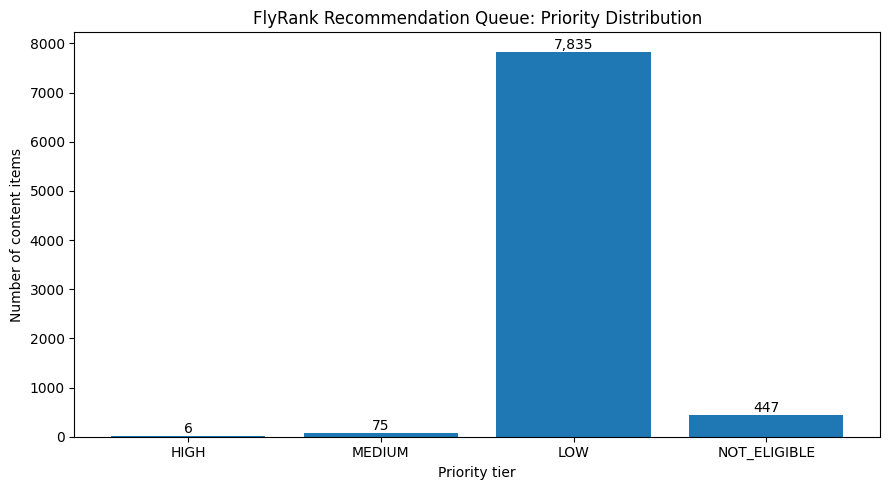

In [4]:

priority_counts = (
    df_heldout_queue["priority_tier"]
    .value_counts()
    .reindex(["HIGH", "MEDIUM", "LOW", "NOT_ELIGIBLE"])
    .dropna()
)

plt.figure(figsize=(9, 5))
bars = plt.bar(priority_counts.index, priority_counts.values)

plt.title("FlyRank Recommendation Queue: Priority Distribution")
plt.xlabel("Priority tier")
plt.ylabel("Number of content items")

for bar, value in zip(bars, priority_counts.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{int(value):,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


## Lambda Scores and Ranking Positions

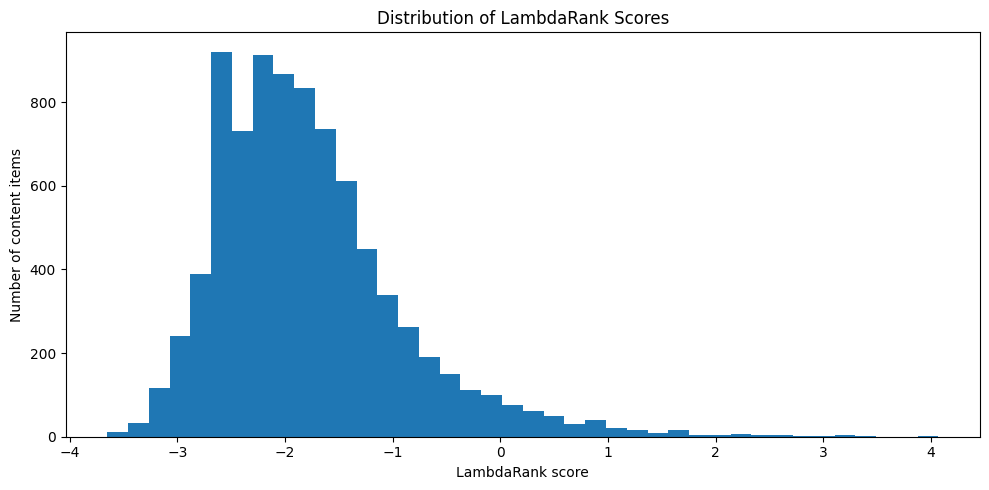

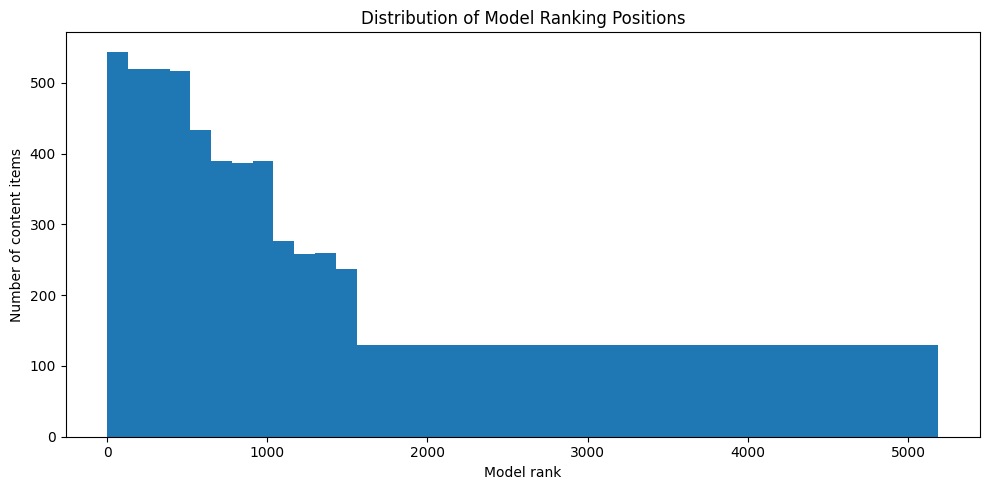

In [5]:

plt.figure(figsize=(10, 5))
plt.hist(
    df_heldout_queue["lambdarank_score"].dropna(),
    bins=40
)
plt.title("Distribution of LambdaRank Scores")
plt.xlabel("LambdaRank score")
plt.ylabel("Number of content items")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.hist(
    df_heldout_queue["model_rank"].dropna(),
    bins=40
)
plt.title("Distribution of Model Ranking Positions")
plt.xlabel("Model rank")
plt.ylabel("Number of content items")
plt.tight_layout()
plt.show()


In [6]:

# Inspect the top 10 recommendations for one client
client_id = df_heldout_queue["client_hash_id"].iloc[0]

client_top10 = (
    df_heldout_queue[
        df_heldout_queue["client_hash_id"] == client_id
    ]
    .sort_values("model_rank")
    .head(10)
)

display(
    client_top10[
        [
            "client_hash_id",
            "content_hash_id",
            "model_rank",
            "priority_tier",
            "recommendation_eligible",
            "lambdarank_score",
            "target_trend_pct",
            "suggested_action",
        ]
    ]
)


,client_hash_id,content_hash_id,model_rank,priority_tier,recommendation_eligible,lambdarank_score,target_trend_pct,suggested_action
0,client_08a6a72ff48e62c0,content_b15bb01e85013477,1,MEDIUM,True,3.239380,-0.924834,"Review search intent, title/meta description, ..."
1,client_08a6a72ff48e62c0,content_a7296d5fc22a04ac,2,MEDIUM,True,3.185243,-0.516973,"Review search intent, title/meta description, ..."
2,client_08a6a72ff48e62c0,content_90ff4e763f53db71,3,MEDIUM,True,3.009784,-0.920404,"Review search intent, title/meta description, ..."
3,client_08a6a72ff48e62c0,content_3ccf7b567d9deea3,4,MEDIUM,True,2.976977,-0.734382,"Review search intent, title/meta description, ..."
4,client_08a6a72ff48e62c0,content_0c82ab20843cc5f3,5,MEDIUM,True,2.792704,-0.955730,"Review search intent, title/meta description, ..."
5,client_08a6a72ff48e62c0,content_de6084567337fb5a,6,MEDIUM,True,2.688173,-0.808584,"Review search intent, title/meta description, ..."
6,client_08a6a72ff48e62c0,content_935fbc6f9bfd304c,7,MEDIUM,True,2.588493,-0.923508,"Review search intent, title/meta description, ..."
7,client_08a6a72ff48e62c0,content_9e6b4bf5b5f092b1,8,MEDIUM,True,2.562056,-0.751669,"Review search intent, title/meta description, ..."
8,client_08a6a72ff48e62c0,content_474063ecb869984b,9,MEDIUM,True,2.511391,-0.716049,"Review search intent, title/meta description, ..."
9,client_08a6a72ff48e62c0,content_003ecfeb2a98c909,10,MEDIUM,True,2.490187,-0.775848,"Review search intent, title/meta description, ..."


## Model Evaluation with NDCG

In [7]:
display(
    df_ndcg_summary.sort_values(
        ["k", "mean_ndcg"],
        ascending=[True, False]
    )
)


,method,k,mean_ndcg,std_ndcg,median_ndcg,p10_ndcg,p90_ndcg,clients_evaluated
0,lambdarank_score,5,0.346066,0.286431,0.269103,0.016350,0.740821,33
1,impressions_baseline_score,5,0.247174,0.289604,0.122987,0.002286,0.521293,33
2,baseline_score,5,0.216390,0.205218,0.153292,0.000000,0.497074,33
3,lambdarank_score,10,0.381323,0.251853,0.315465,0.106768,0.725742,33
4,impressions_baseline_score,10,0.262650,0.277993,0.171256,0.023868,0.527211,33
5,baseline_score,10,0.246187,0.176020,0.238992,0.074128,0.418551,33


## Variablity Accross Clients

<Figure size 1000x500 with 0 Axes>

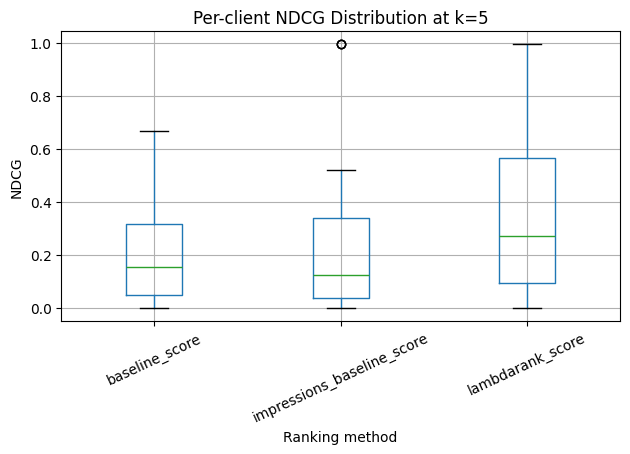

<Figure size 1000x500 with 0 Axes>

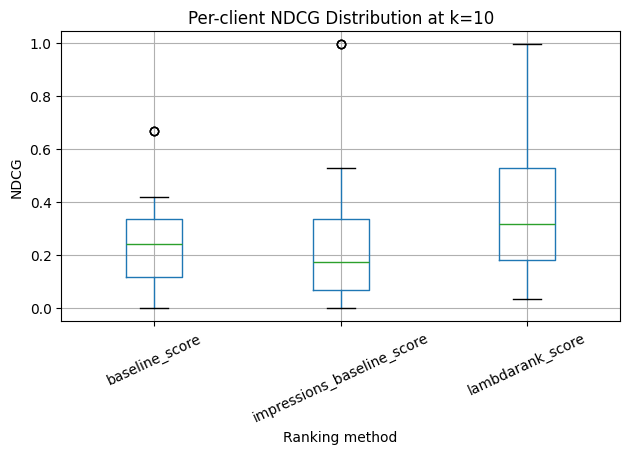

In [8]:
for k_value in sorted(df_ndcg_per_client["k"].dropna().unique()):
    subset = df_ndcg_per_client[
        df_ndcg_per_client["k"] == k_value
    ]

    plt.figure(figsize=(10, 5))
    subset.boxplot(
        column="ndcg",
        by="method",
        rot=25
    )

    plt.suptitle("")
    plt.title(f"Per-client NDCG Distribution at k={k_value}")
    plt.xlabel("Ranking method")
    plt.ylabel("NDCG")
    plt.tight_layout()
    plt.show()


## Feature Importance

,feature,importance_value
0,feat_pos_volatility_60_90,1269
1,feat_imp_log_ratio,1163
2,log_feat_imp_60_90,1153
3,feat_pos_90_120,1105
4,feat_pos_60_90,1094
5,feat_position_change,975
6,log_feat_imp_90_120,940
7,feat_ctr_90_120,669
8,feat_ctr_60_90,586
9,feat_active_days_90_120,520


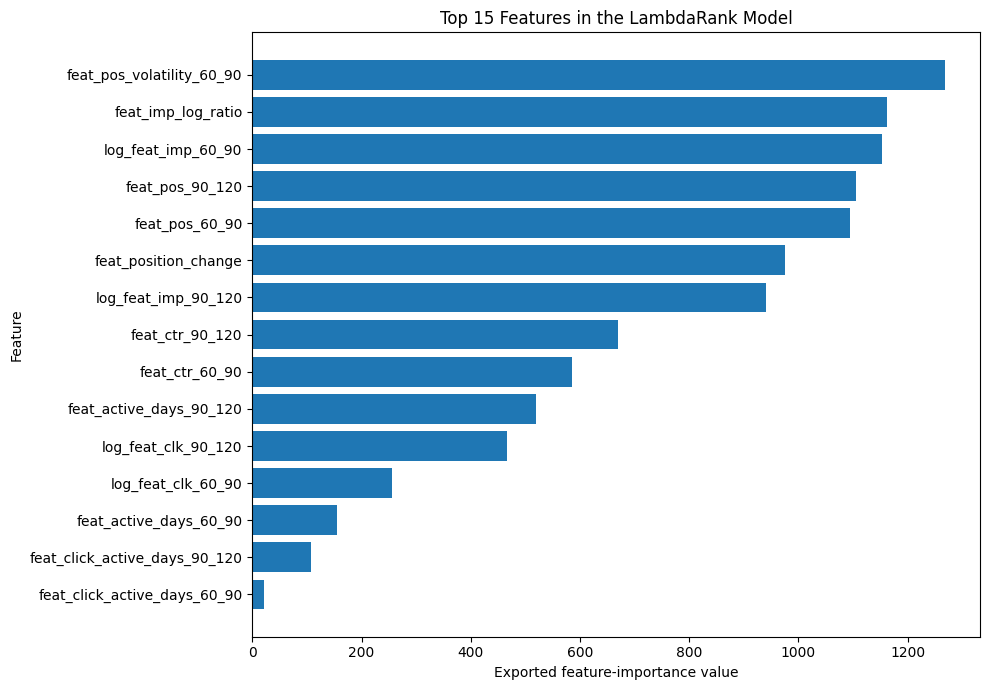

In [9]:

importance = df_feature_importance.copy()

# The feature names are stored in the first column in your CSV.
feature_col = (
    "feature"
    if "feature" in importance.columns
    else "Unnamed: 0"
)

importance = importance.rename(
    columns={
        feature_col: "feature",
        "importance": "importance_value"
    }
)

importance["importance_value"] = pd.to_numeric(
    importance["importance_value"],
    errors="coerce"
)

importance = importance.dropna(
    subset=["importance_value"]
).sort_values(
    "importance_value",
    ascending=False
)

display(importance.head(20))

top_features = importance.head(15).sort_values(
    "importance_value",
    ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_features["feature"],
    top_features["importance_value"]
)
plt.title("Top 15 Features in the LambdaRank Model")
plt.xlabel("Exported feature-importance value")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


## Google Search Console Coverage

,gsc_availability_status,rows,impressions_null_rows,clicks_null_rows,position_null_rows,explicit_zero_impression_rows,available_but_impressions_missing
0,available_false,27536539,0,0,27536539,27536539,0
1,available_true,15558874,0,0,46,0,0


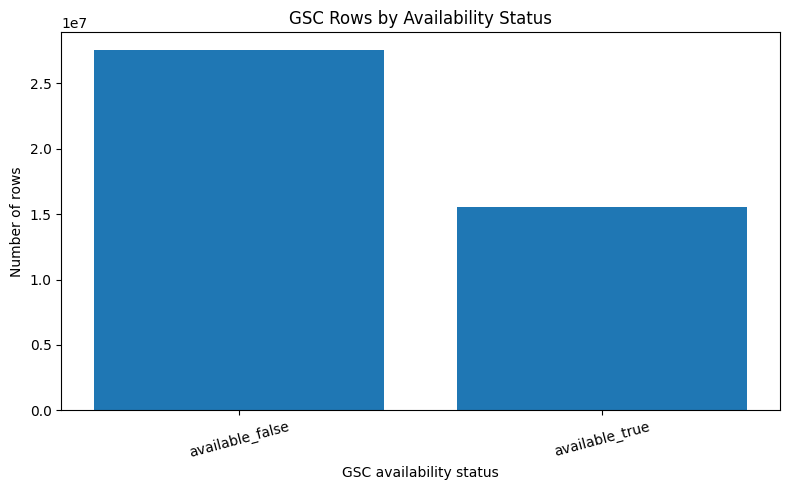

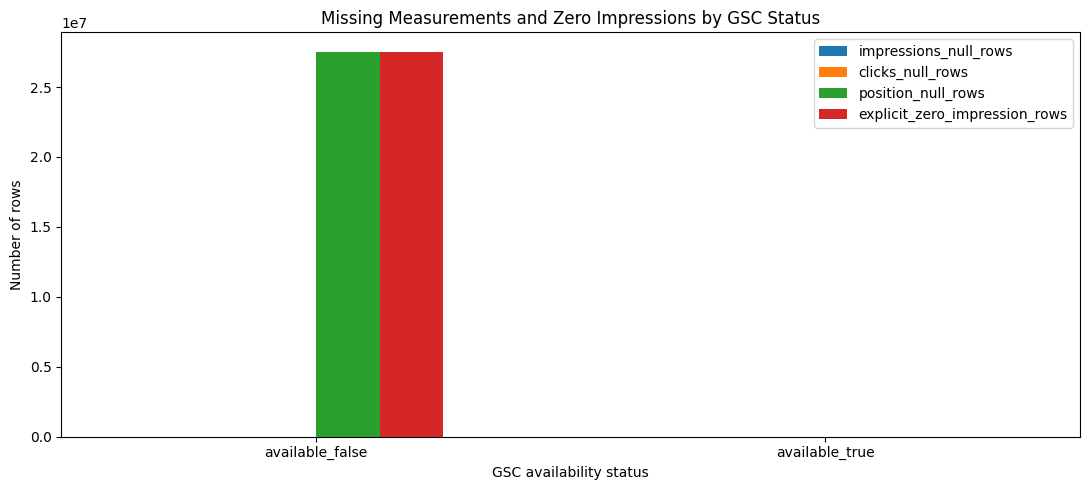

In [10]:

display(df_gsc_coverage)

coverage = df_gsc_coverage.copy()

plt.figure(figsize=(8, 5))
plt.bar(
    coverage["gsc_availability_status"],
    coverage["rows"]
)
plt.title("GSC Rows by Availability Status")
plt.xlabel("GSC availability status")
plt.ylabel("Number of rows")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

coverage_columns = [
    "impressions_null_rows",
    "clicks_null_rows",
    "position_null_rows",
    "explicit_zero_impression_rows",
]

available_columns = [
    column for column in coverage_columns
    if column in coverage.columns
]

coverage.set_index(
    "gsc_availability_status"
)[available_columns].plot(
    kind="bar",
    figsize=(11, 5)
)

plt.title("Missing Measurements and Zero Impressions by GSC Status")
plt.xlabel("GSC availability status")
plt.ylabel("Number of rows")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## CTR Missingness

,feature,rows,missing_rows,missing_pct,reason_note
0,feat_ctr_60_90,78904,0,0.0,Missing clicks/impressions or zero impressions
1,feat_ctr_90_120,78904,0,0.0,Missing clicks/impressions or zero impressions


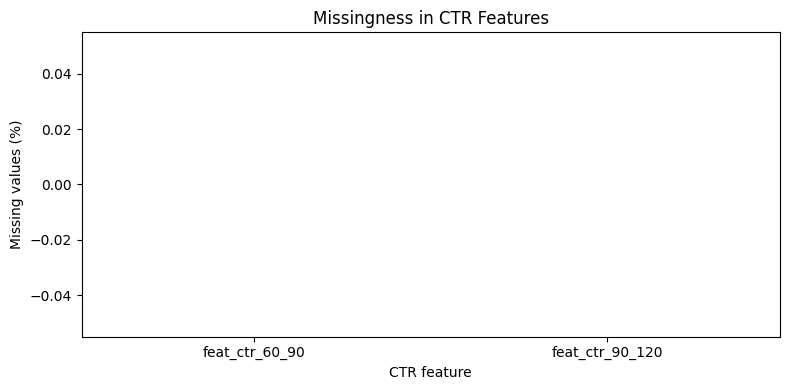

In [11]:

display(df_ctr_missingness)

ctr_audit = df_ctr_missingness.copy()

plt.figure(figsize=(8, 4))
plt.bar(
    ctr_audit["feature"],
    ctr_audit["missing_pct"]
)
plt.title("Missingness in CTR Features")
plt.xlabel("CTR feature")
plt.ylabel("Missing values (%)")
plt.tight_layout()
plt.show()


## Split Diagnostics

,split_seed,train_clients,test_clients,train_rows_after_cap,train_rows_before_cap,test_rows_full,sampled_train_clients,max_train_group_after_cap
0,11,25,7,41822,52179,26721,1,10000
1,23,25,7,51328,55754,23146,2,10000
2,42,25,7,48108,61446,17454,2,10000
3,61,25,7,34476,44833,34067,1,10000
4,97,25,7,55754,70537,8363,3,10000


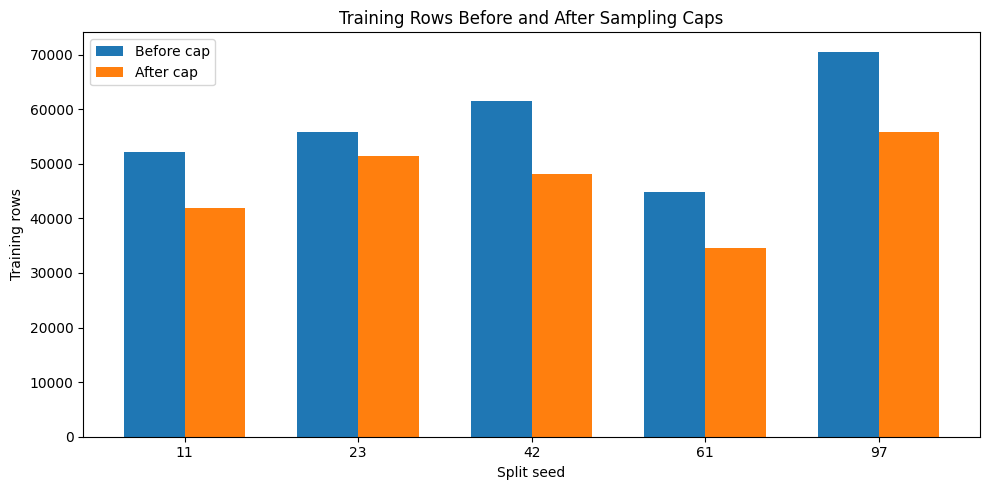

In [12]:

display(df_split_diagnostics)

plt.figure(figsize=(10, 5))
x = np.arange(len(df_split_diagnostics))
width = 0.35

plt.bar(
    x - width / 2,
    df_split_diagnostics["train_rows_before_cap"],
    width,
    label="Before cap"
)
plt.bar(
    x + width / 2,
    df_split_diagnostics["train_rows_after_cap"],
    width,
    label="After cap"
)

plt.xticks(
    x,
    df_split_diagnostics["split_seed"].astype(str)
)
plt.title("Training Rows Before and After Sampling Caps")
plt.xlabel("Split seed")
plt.ylabel("Training rows")
plt.legend()
plt.tight_layout()
plt.show()


# Additional EDA: Client-Level Model Comparison, Recommendation Distribution, and Ranking Diagnostics

This section extends the existing EDA notebook and reuses the DataFrames already loaded:
- `df_heldout_queue`
- `df_ndcg_per_client`
- `df_ndcg_summary`

It does not reload the CSVs. Column names are inspected before analysis, because exported schemas can differ slightly between pipeline versions.

**Interpretation:** NDCG measures ranking agreement with the historical relevance labels; it does not measure causal traffic uplift from refreshing a page.

## A. Client-by-client model comparison

We compare LambdaRank against the impressions-only and rule-based baselines at NDCG@5 and NDCG@10. The paired comparison is performed within the same split seed, client, and `k` whenever those columns are available. This avoids comparing unrelated client/split observations.

In [13]:
# 1. Inspect the evaluation schema first
print("df_ndcg_per_client columns:")
print(df_ndcg_per_client.columns.tolist())
display(df_ndcg_per_client.head())

# Normalize likely column names without overwriting the original DataFrame.
eval_df = df_ndcg_per_client.copy()
eval_df.columns = [str(c).strip() for c in eval_df.columns]

def first_existing(df, candidates):
    return next((c for c in candidates if c in df.columns), None)

client_col = first_existing(eval_df, ["client_hash_id", "client_id", "client"])
seed_col = first_existing(eval_df, ["split_seed", "seed", "split", "split_id"])
method_col = first_existing(eval_df, ["method", "model", "ranking_method", "baseline"])
k_col = first_existing(eval_df, ["k", "cutoff", "top_k"])
score_col = first_existing(eval_df, ["ndcg", "ndcg_score", "score", "value"])

required = {"client": client_col, "method": method_col, "k": k_col, "ndcg": score_col}
missing_required = [name for name, col in required.items() if col is None]
if missing_required:
    raise ValueError(
        "Cannot build client-level comparison; missing columns for: "
        + ", ".join(missing_required)
        + ". Inspect the printed schema and adjust the column mapping."
    )

rename_map = {client_col: "client_id", method_col: "method", k_col: "k", score_col: "ndcg"}
if seed_col:
    rename_map[seed_col] = "split_seed"
eval_df = eval_df.rename(columns=rename_map)

eval_df["k"] = pd.to_numeric(eval_df["k"], errors="coerce")
eval_df["ndcg"] = pd.to_numeric(eval_df["ndcg"], errors="coerce")
eval_df = eval_df.dropna(subset=["client_id", "method", "k", "ndcg"])
eval_df = eval_df[eval_df["k"].isin([5, 10])]

print("Evaluation rows after cleaning:", len(eval_df))
print("Unique clients:", eval_df["client_id"].nunique())
print("Methods:", sorted(eval_df["method"].astype(str).unique()))
print("k values:", sorted(eval_df["k"].unique()))


df_ndcg_per_client columns:
['split_seed', 'client_hash_id', 'method', 'k', 'ndcg', 'rows_in_client', 'positive_relevance_rows']


,split_seed,client_hash_id,method,k,ndcg,rows_in_client,positive_relevance_rows
0,11,client_1a730cb2640a1abf,lambdarank_score,5,0.338259,1054,263
1,11,client_1a730cb2640a1abf,lambdarank_score,10,0.245615,1054,263
2,11,client_2094c6eb080311d5,lambdarank_score,5,0.111486,884,328
3,11,client_2094c6eb080311d5,lambdarank_score,10,0.074888,884,328
4,11,client_23a62021009f63c4,lambdarank_score,5,0.238952,11445,8445


Evaluation rows after cleaning: 198
Unique clients: 22
Methods: ['baseline_score', 'impressions_baseline_score', 'lambdarank_score']
k values: [np.int64(5), np.int64(10)]


In [14]:
# 2. Inspect exact method labels, then map them to comparable method groups.
method_labels = eval_df["method"].astype(str).unique().tolist()
print("Exact method labels:", method_labels)

def classify_method(label):
    s = str(label).lower().replace("_", " ").replace("-", " ")
    if "lambda" in s or "ranker" in s:
        return "LambdaRank"
    if "impression" in s:
        return "Impressions baseline"
    if "rule" in s:
        return "Rule-based baseline"
    return None

eval_df["method_group"] = eval_df["method"].map(classify_method)
unmapped = sorted(eval_df.loc[eval_df["method_group"].isna(), "method"].astype(str).unique())
if unmapped:
    print("WARNING: Unmapped method labels (review these):", unmapped)

eval_df = eval_df.dropna(subset=["method_group"])
group_cols = ["client_id"] + (["split_seed"] if "split_seed" in eval_df.columns else []) + ["k", "method_group"]
duplicates = eval_df.duplicated(group_cols, keep=False)
if duplicates.any():
    print("WARNING: Duplicate client/split/k/method records:", int(duplicates.sum()))
    print("Aggregating duplicates by mean NDCG for plotting; investigate their origin.")
    eval_df = eval_df.groupby(group_cols, as_index=False)["ndcg"].mean()

display(
    eval_df.groupby(["method_group", "k"])["ndcg"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(4)
)


Exact method labels: ['lambdarank_score', 'baseline_score', 'impressions_baseline_score']


count    mean  median     std     min     max
method_group         k                                                
Impressions baseline 5      33  0.2472  0.1230  0.2896  0.0000  0.9942
                     10     33  0.2627  0.1713  0.2780  0.0000  0.9942
LambdaRank           5      33  0.3461  0.2691  0.2864  0.0000  0.9942
                     10     33  0.3813  0.3155  0.2519  0.0315  0.9942

In [15]:
# 3. Paired differences: LambdaRank minus each baseline.
pair_keys = ["client_id"] + (["split_seed"] if "split_seed" in eval_df.columns else []) + ["k"]
wide = eval_df.pivot_table(
    index=pair_keys,
    columns="method_group",
    values="ndcg",
    aggfunc="mean"
).reset_index()

comparison_rows = []
for baseline in ["Impressions baseline", "Rule-based baseline"]:
    if "LambdaRank" not in wide.columns or baseline not in wide.columns:
        print(f"Cannot compare against {baseline}: required method not present.")
        continue
    valid = wide[["LambdaRank", baseline]].dropna()
    diff = valid["LambdaRank"] - valid[baseline]
    comparison_rows.append({
        "baseline": baseline,
        "k": int(valid.index.size) if False else None,
        "paired_observations": int(len(valid)),
        "lambda_wins": int((diff > 0).sum()),
        "ties": int((diff == 0).sum()),
        "lambda_losses": int((diff < 0).sum()),
        "win_rate_pct_excluding_ties": round(100 * (diff > 0).sum() / max((diff != 0).sum(), 1), 2),
        "mean_difference": float(diff.mean()) if len(diff) else np.nan,
        "median_difference": float(diff.median()) if len(diff) else np.nan,
    })
display(pd.DataFrame(comparison_rows))

# Per-k paired differences and win rates
detailed = []
for k_value in [5, 10]:
    part = wide[wide["k"] == k_value]
    for baseline in ["Impressions baseline", "Rule-based baseline"]:
        if "LambdaRank" not in part.columns or baseline not in part.columns:
            continue
        valid = part[["LambdaRank", baseline]].dropna()
        diff = valid["LambdaRank"] - valid[baseline]
        non_ties = int((diff != 0).sum())
        detailed.append({
            "k": k_value,
            "baseline": baseline,
            "paired_client_split_rows": len(valid),
            "lambda_wins": int((diff > 0).sum()),
            "ties": int((diff == 0).sum()),
            "lambda_losses": int((diff < 0).sum()),
            "win_rate_excluding_ties_pct": round(100 * (diff > 0).sum() / max(non_ties, 1), 2),
            "mean_delta_ndcg": diff.mean(),
            "median_delta_ndcg": diff.median(),
        })
paired_summary = pd.DataFrame(detailed)
display(paired_summary.round(4))


Cannot compare against Rule-based baseline: required method not present.


,baseline,k,paired_observations,lambda_wins,ties,lambda_losses,win_rate_pct_excluding_ties,mean_difference,median_difference
0,Impressions baseline,None,66,45,4,17,72.58,0.108783,0.043312


,k,baseline,paired_client_split_rows,lambda_wins,ties,lambda_losses,win_rate_excluding_ties_pct,mean_delta_ndcg,median_delta_ndcg
0,5,Impressions baseline,33,21,3,9,70.0,0.0989,0.0242
1,10,Impressions baseline,33,24,1,8,75.0,0.1187,0.0778


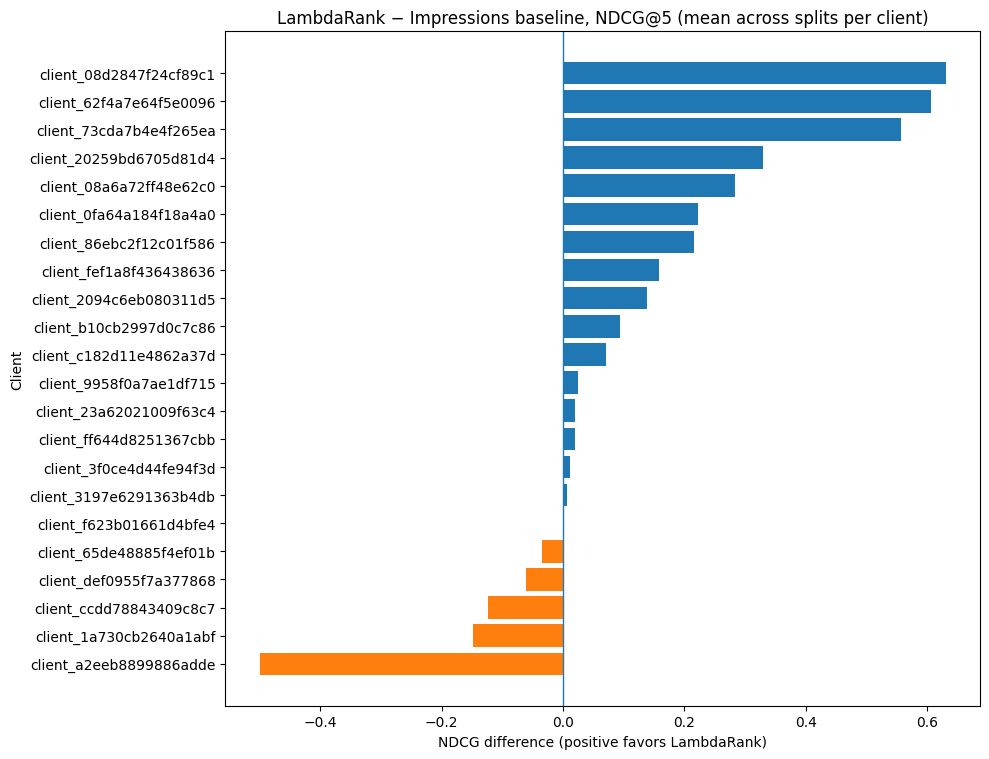

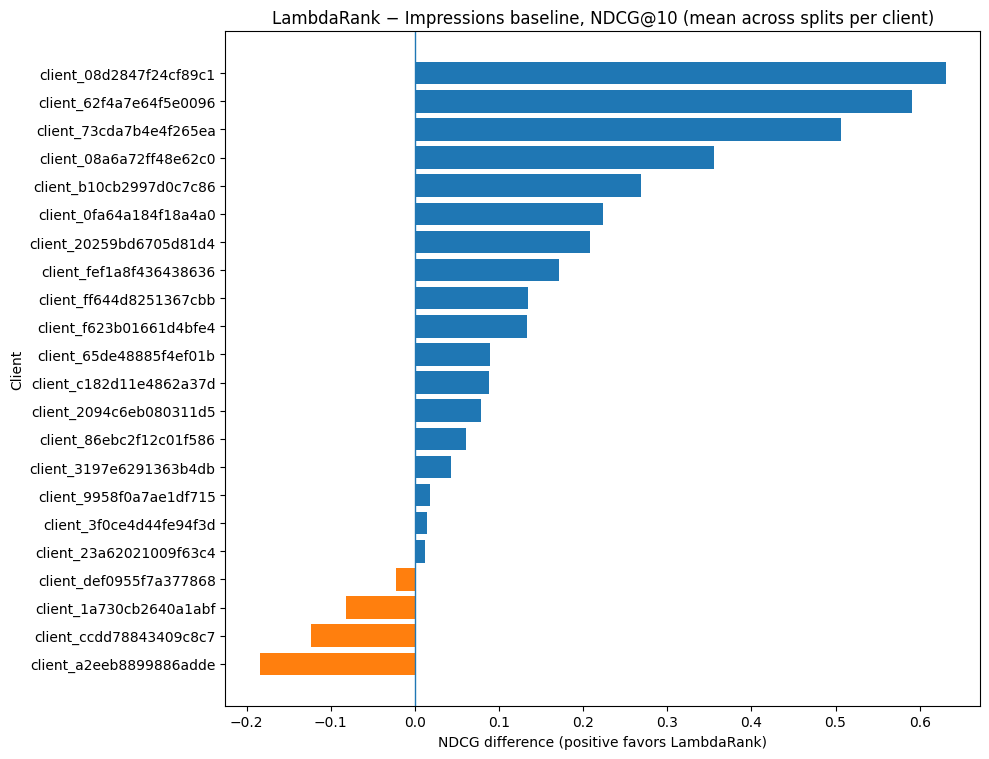

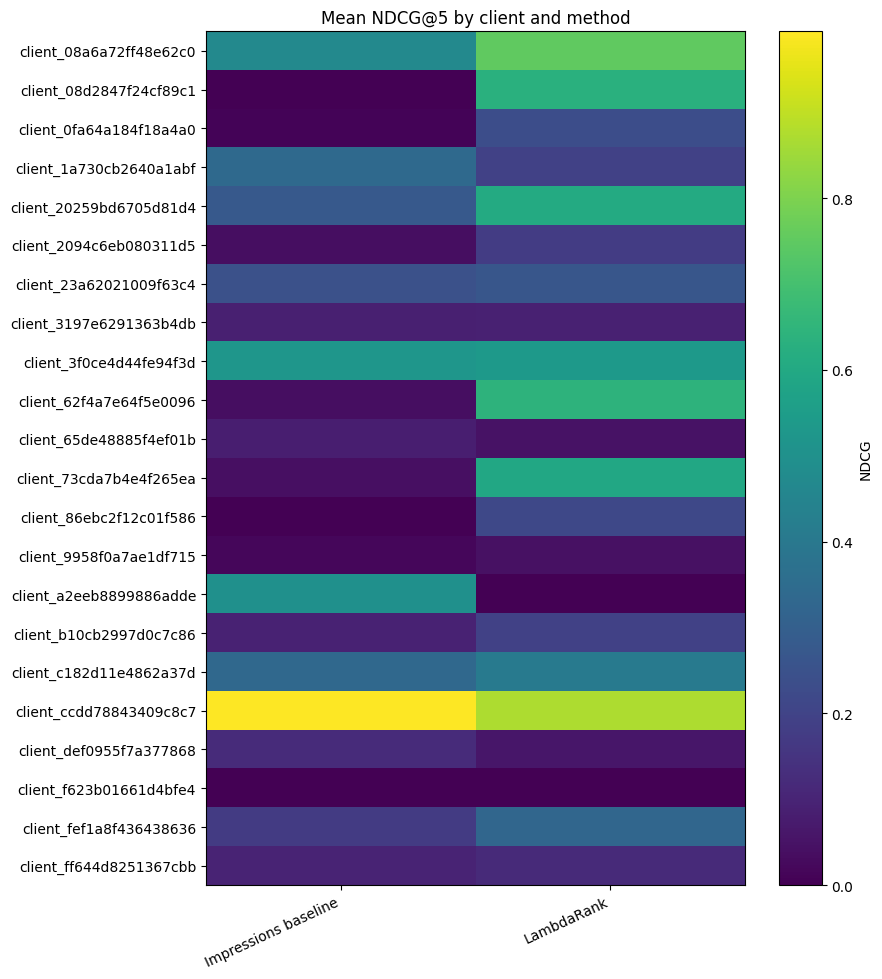

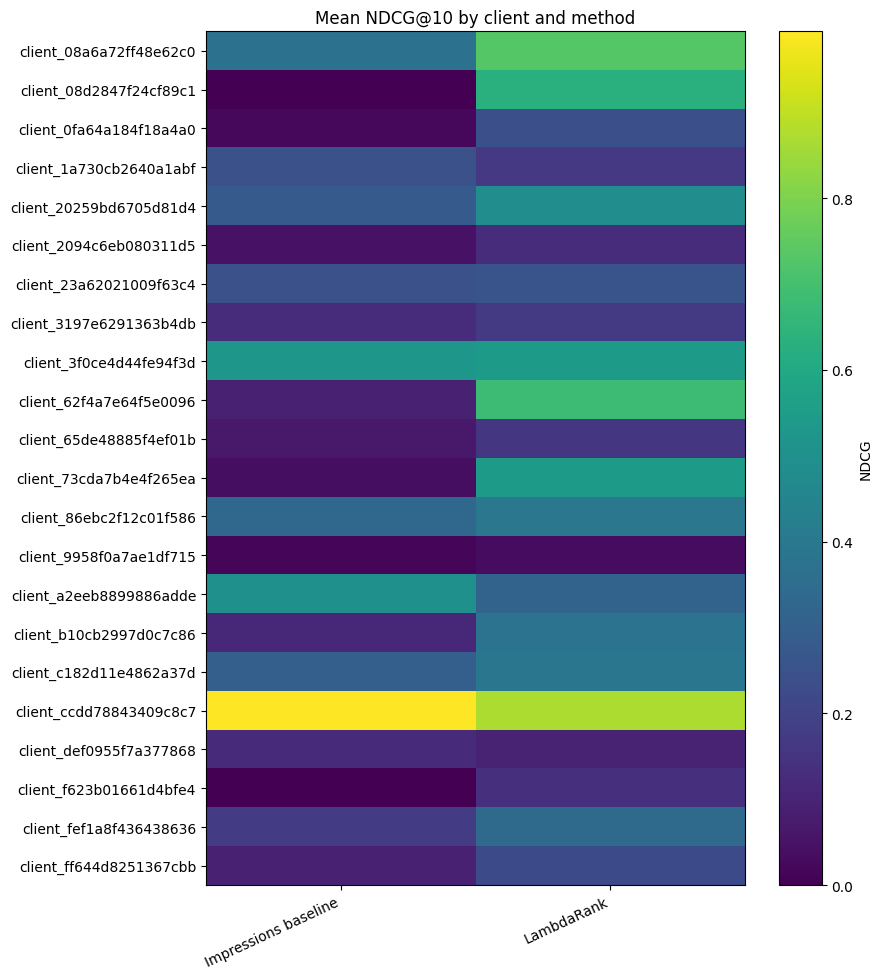

In [16]:
# 4. Paired difference plots and client-by-method heatmaps.
for k_value in [5, 10]:
    part = wide[wide["k"] == k_value].copy()
    for baseline in ["Impressions baseline", "Rule-based baseline"]:
        if "LambdaRank" not in part.columns or baseline not in part.columns:
            continue
        part["delta"] = part["LambdaRank"] - part[baseline]
        plot_part = part.dropna(subset=["delta"]).copy()
        if plot_part.empty:
            continue

        # If there are repeated split seeds, aggregate the differences per client for readability.
        client_delta = plot_part.groupby("client_id", as_index=False)["delta"].mean()
        client_delta = client_delta.sort_values("delta")

        plt.figure(figsize=(10, max(4, min(12, 0.35 * len(client_delta)))))
        colors = np.where(client_delta["delta"] >= 0, "tab:blue", "tab:orange")
        plt.barh(client_delta["client_id"].astype(str), client_delta["delta"], color=colors)
        plt.axvline(0, linewidth=1)
        plt.title(f"LambdaRank − {baseline}, NDCG@{k_value} (mean across splits per client)")
        plt.xlabel("NDCG difference (positive favors LambdaRank)")
        plt.ylabel("Client")
        plt.tight_layout()
        plt.show()

# Heatmap of per-client average NDCG for each method and k.
heat = eval_df.groupby(["client_id", "method_group", "k"], as_index=False)["ndcg"].mean()
for k_value in [5, 10]:
    mat = heat[heat["k"] == k_value].pivot(index="client_id", columns="method_group", values="ndcg")
    if mat.empty:
        continue
    fig, ax = plt.subplots(figsize=(9, max(4, 0.45 * len(mat))))
    im = ax.imshow(mat.values, aspect="auto", interpolation="nearest")
    ax.set_xticks(range(len(mat.columns)), mat.columns, rotation=25, ha="right")
    ax.set_yticks(range(len(mat.index)), mat.index.astype(str))
    ax.set_title(f"Mean NDCG@{k_value} by client and method")
    fig.colorbar(im, ax=ax, label="NDCG")
    plt.tight_layout()
    plt.show()


In [17]:
# 5. Biggest client-level wins and losses (averaged across split seeds, if present).
for k_value in [5, 10]:
    part = wide[wide["k"] == k_value].copy()
    for baseline in ["Impressions baseline", "Rule-based baseline"]:
        if "LambdaRank" not in part.columns or baseline not in part.columns:
            continue
        part["delta"] = part["LambdaRank"] - part[baseline]
        client_delta = part.groupby("client_id", as_index=False)["delta"].mean().dropna()
        client_delta = client_delta.sort_values("delta")
        print(f"\nNDCG@{k_value}: LambdaRank minus {baseline} — biggest losses")
        display(client_delta.head(5))
        print(f"NDCG@{k_value}: LambdaRank minus {baseline} — biggest wins")
        display(client_delta.tail(5).sort_values("delta", ascending=False))



NDCG@5: LambdaRank minus Impressions baseline — biggest losses


,client_id,delta
14,client_a2eeb8899886adde,-0.500000
3,client_1a730cb2640a1abf,-0.148632
17,client_ccdd78843409c8c7,-0.123540
18,client_def0955f7a377868,-0.061494
10,client_65de48885f4ef01b,-0.034070


NDCG@5: LambdaRank minus Impressions baseline — biggest wins


,client_id,delta
1,client_08d2847f24cf89c1,0.630930
9,client_62f4a7e64f5e0096,0.606331
11,client_73cda7b4e4f265ea,0.556948
4,client_20259bd6705d81d4,0.330349
0,client_08a6a72ff48e62c0,0.283502



NDCG@10: LambdaRank minus Impressions baseline — biggest losses


,client_id,delta
14,client_a2eeb8899886adde,-0.184535
17,client_ccdd78843409c8c7,-0.123540
3,client_1a730cb2640a1abf,-0.081587
18,client_def0955f7a377868,-0.022695
6,client_23a62021009f63c4,0.012474


NDCG@10: LambdaRank minus Impressions baseline — biggest wins


,client_id,delta
1,client_08d2847f24cf89c1,0.630930
9,client_62f4a7e64f5e0096,0.591012
11,client_73cda7b4e4f265ea,0.505885
0,client_08a6a72ff48e62c0,0.355816
15,client_b10cb2997d0c7c86,0.268433


## B. Recommendation distribution by client

This section checks recommendation volume, priority-tier composition, and eligibility per client. Because the available queue is named `heldout_recommendation_queue`, these statistics describe that exported queue only; they should not be presented as full production coverage without verifying the producing pipeline.

In [18]:
queue = df_heldout_queue.copy()
print("Queue columns:", queue.columns.tolist())

client_key = first_existing(queue, ["client_hash_id", "client_id", "client"])
tier_key = first_existing(queue, ["priority_tier", "priority", "tier"])
eligible_key = first_existing(queue, ["recommendation_eligible", "eligible", "is_eligible"])
content_key = first_existing(queue, ["content_hash_id", "content_id", "page_id"])

if client_key is None:
    raise ValueError("No client identifier column found in df_heldout_queue.")

queue[client_key] = queue[client_key].astype("string")
print("Queue rows:", len(queue))
print("Unique clients:", queue[client_key].nunique(dropna=True))
if content_key:
    print("Unique content identifiers:", queue[content_key].nunique(dropna=True))
    print("Duplicate client-content pairs:", int(queue.duplicated([client_key, content_key]).sum()))

client_counts = queue.groupby(client_key, dropna=False).size().rename("queue_rows").to_frame()
if content_key:
    client_counts["unique_content_ids"] = queue.groupby(client_key)[content_key].nunique()
if eligible_key:
    eligible_norm = queue[eligible_key].astype("string").str.lower().isin(["true", "1", "yes", "eligible"])
    queue["_eligible_bool"] = eligible_norm
    client_counts["eligible_rows"] = queue.groupby(client_key)["_eligible_bool"].sum()
    client_counts["eligible_pct"] = (100 * client_counts["eligible_rows"] / client_counts["queue_rows"]).round(2)
display(client_counts.sort_values("queue_rows", ascending=False))


Queue columns: ['client_hash_id', 'content_hash_id', 'model_rank', 'priority_tier', 'recommendation_eligible', 'high_priority_evidence', 'historical_decline_evidence', 'lambdarank_score', 'baseline_rank', 'baseline_score', 'target_trend_pct', 'target_imp_prev30', 'target_imp_last30', 'target_observed_days_prev30', 'target_observed_days_last30', 'feat_imp_60_90', 'feat_imp_90_120', 'feat_imp_log_ratio', 'feat_active_days_60_90', 'feat_pos_60_90', 'feat_ctr_60_90', 'suggested_action', 'visible_queries', 'rare_share', 'anon_share', 'top_query_impressions', 'kept_query_impressions', 'top_query_share']
Queue rows: 8363
Unique clients: 7
Unique content identifiers: 8363
Duplicate client-content pairs: 0


,queue_rows,unique_content_ids,eligible_rows,eligible_pct
client_hash_id,,,,
client_08a6a72ff48e62c0,5189,5189,4832,93.12
client_3f0ce4d44fe94f3d,1534,1534,1504,98.04
client_1a730cb2640a1abf,1054,1054,1037,98.39
client_ff644d8251367cbb,562,562,520,92.53
client_08d2847f24cf89c1,13,13,12,92.31
client_86ebc2f12c01f586,7,7,7,100.00
client_ccdd78843409c8c7,4,4,4,100.00


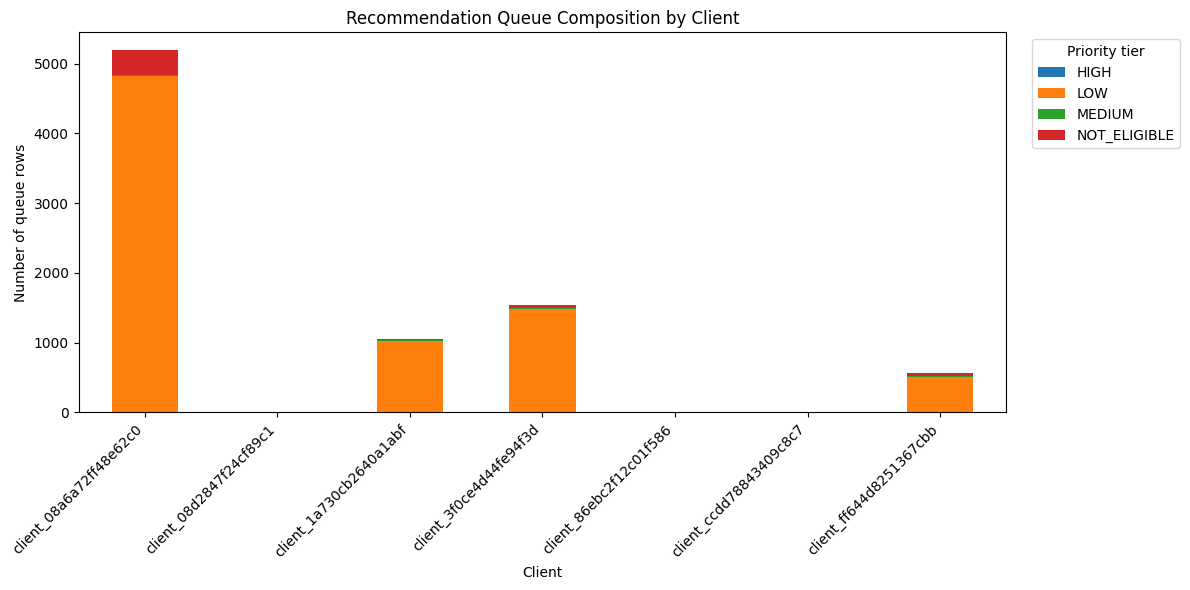

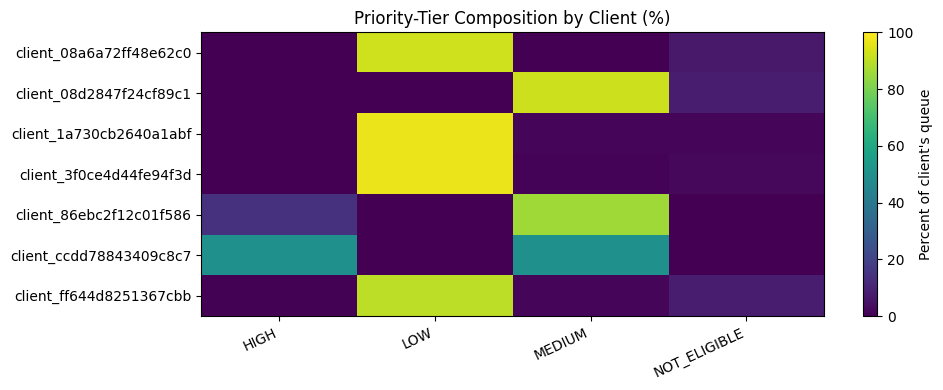

,queue_rows,eligible_rows,eligible_pct
client_hash_id,,,
client_08d2847f24cf89c1,13,12,92.307692
client_ff644d8251367cbb,562,520,92.526690
client_08a6a72ff48e62c0,5189,4832,93.120062
client_3f0ce4d44fe94f3d,1534,1504,98.044329
client_1a730cb2640a1abf,1054,1037,98.387097
client_86ebc2f12c01f586,7,7,100.000000
client_ccdd78843409c8c7,4,4,100.000000


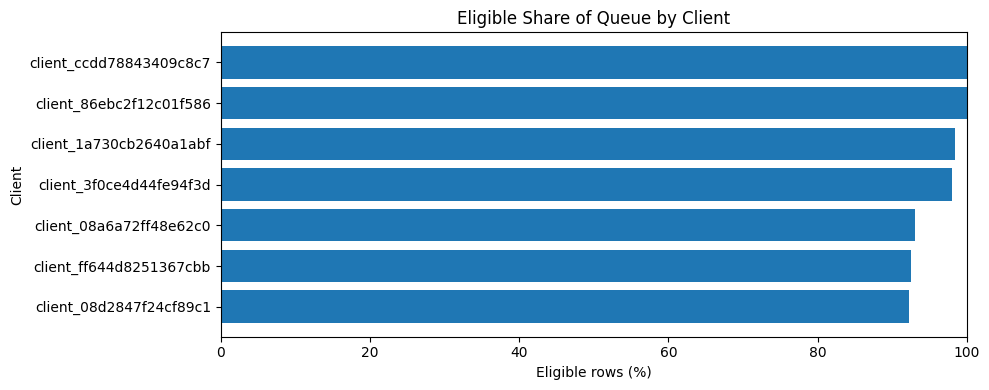

In [19]:
# Stacked counts of priority tiers by client.
if tier_key:
    tier_counts = pd.crosstab(queue[client_key], queue[tier_key].fillna("MISSING"))
    ax = tier_counts.plot(kind="bar", stacked=True, figsize=(12, 6))
    ax.set_title("Recommendation Queue Composition by Client")
    ax.set_xlabel("Client")
    ax.set_ylabel("Number of queue rows")
    ax.legend(title="Priority tier", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

    # Heatmap of within-client tier percentages.
    tier_pct = tier_counts.div(tier_counts.sum(axis=1).replace(0, np.nan), axis=0) * 100
    fig, ax = plt.subplots(figsize=(10, max(4, 0.45 * len(tier_pct))))
    im = ax.imshow(tier_pct.fillna(0).values, aspect="auto", interpolation="nearest", vmin=0, vmax=100)
    ax.set_xticks(range(len(tier_pct.columns)), tier_pct.columns, rotation=25, ha="right")
    ax.set_yticks(range(len(tier_pct.index)), tier_pct.index.astype(str))
    ax.set_title("Priority-Tier Composition by Client (%)")
    fig.colorbar(im, ax=ax, label="Percent of client's queue")
    plt.tight_layout()
    plt.show()

if eligible_key:
    eligibility_summary = queue.groupby(client_key)["_eligible_bool"].agg(["count", "sum", "mean"])
    eligibility_summary["eligible_pct"] = eligibility_summary["mean"] * 100
    eligibility_summary = eligibility_summary.sort_values("eligible_pct")
    display(eligibility_summary[["count", "sum", "eligible_pct"]].rename(
        columns={"count": "queue_rows", "sum": "eligible_rows"}
    ))
    plt.figure(figsize=(10, max(4, 0.4 * len(eligibility_summary))))
    plt.barh(eligibility_summary.index.astype(str), eligibility_summary["eligible_pct"])
    plt.xlim(0, 100)
    plt.title("Eligible Share of Queue by Client")
    plt.xlabel("Eligible rows (%)")
    plt.ylabel("Client")
    plt.tight_layout()
    plt.show()


## C. Priority-tier and ranking-score diagnostics

We check whether model rank and score are aligned, how scores vary by priority tier, and whether ineligible rows appear in the exported queue. Some checks depend on the actual schema; missing fields are reported rather than assumed.

Detected fields: {'client': 'client_hash_id', 'tier': 'priority_tier', 'eligibility': 'recommendation_eligible', 'score': 'lambdarank_score', 'rank': 'model_rank'}
Missing/non-numeric scores: 0
Infinite scores: 0


,count,mean,median,std,min,max
priority_tier,,,,,,
MEDIUM,75,0.589332,0.561764,1.902155,-3.320711,4.069206
HIGH,6,-0.415821,-0.192525,0.945592,-1.571050,0.543298
NOT_ELIGIBLE,447,-1.596050,-1.652861,0.563578,-2.844659,0.339630
LOW,7835,-1.819663,-1.953035,0.832088,-3.651092,1.975892


/tmp/ipykernel_564/3066531364.py:25: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(plot_data, labels=[str(t) for t in tier_order], showfliers=False)


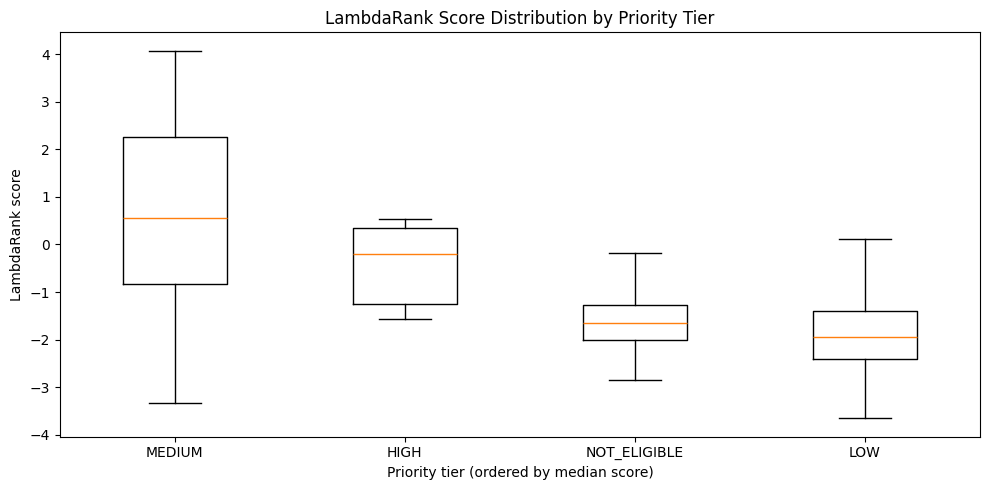

Missing/non-numeric ranks: 0
Ranks below 1: 0
Spearman correlation between rank and score: -0.6232


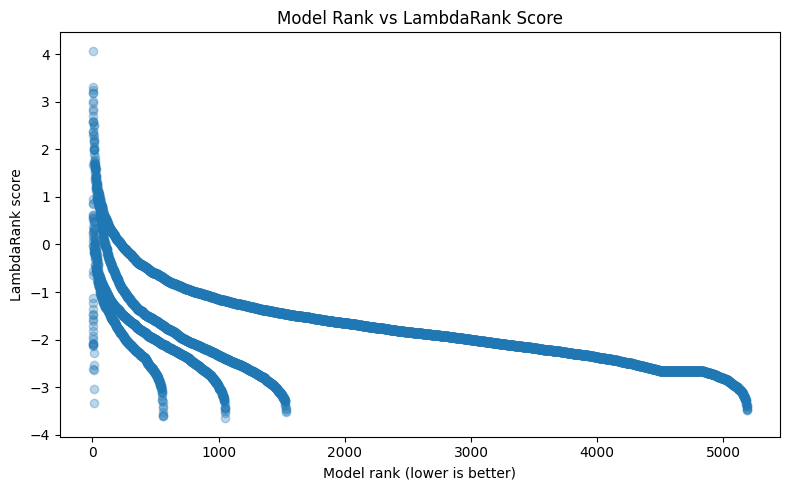

Eligibility by priority tier:


_eligible_bool,False,True,All
priority_tier,,,
HIGH,0,6,6
LOW,0,7835,7835
MEDIUM,0,75,75
NOT_ELIGIBLE,447,0,447
All,447,7916,8363


Ineligible rows assigned a potentially actionable tier: 0


In [20]:
score_key = first_existing(queue, ["lambdarank_score", "ranker_score", "model_score", "score"])
rank_key = first_existing(queue, ["model_rank", "rank", "rank_position"])
print("Detected fields:", {
    "client": client_key,
    "tier": tier_key,
    "eligibility": eligible_key,
    "score": score_key,
    "rank": rank_key,
})

if score_key:
    queue[score_key] = pd.to_numeric(queue[score_key], errors="coerce")
    print("Missing/non-numeric scores:", int(queue[score_key].isna().sum()))
    print("Infinite scores:", int(np.isinf(queue[score_key].dropna()).sum()))
    if tier_key:
        display(queue.groupby(tier_key, dropna=False)[score_key].agg(
            ["count", "mean", "median", "std", "min", "max"]
        ).sort_values("median", ascending=False))
        plt.figure(figsize=(10, 5))
        tier_order = queue.groupby(tier_key)[score_key].median().sort_values(ascending=False).index
        plot_data = [
            queue.loc[queue[tier_key] == tier, score_key].dropna().values
            for tier in tier_order
        ]
        plt.boxplot(plot_data, labels=[str(t) for t in tier_order], showfliers=False)
        plt.title("LambdaRank Score Distribution by Priority Tier")
        plt.xlabel("Priority tier (ordered by median score)")
        plt.ylabel("LambdaRank score")
        plt.tight_layout()
        plt.show()

if rank_key:
    queue[rank_key] = pd.to_numeric(queue[rank_key], errors="coerce")
    print("Missing/non-numeric ranks:", int(queue[rank_key].isna().sum()))
    print("Ranks below 1:", int((queue[rank_key].dropna() < 1).sum()))
    if score_key:
        valid = queue[[rank_key, score_key]].dropna()
        if len(valid):
            corr = valid[rank_key].corr(valid[score_key], method="spearman")
            print("Spearman correlation between rank and score:", round(float(corr), 4))
            plt.figure(figsize=(8, 5))
            plt.scatter(valid[rank_key], valid[score_key], alpha=0.3)
            plt.title("Model Rank vs LambdaRank Score")
            plt.xlabel("Model rank (lower is better)")
            plt.ylabel("LambdaRank score")
            plt.tight_layout()
            plt.show()

if eligible_key and tier_key:
    queue["_eligible_bool"] = queue[eligible_key].astype("string").str.lower().isin(["true", "1", "yes", "eligible"])
    print("Eligibility by priority tier:")
    display(pd.crosstab(queue[tier_key].fillna("MISSING"), queue["_eligible_bool"], margins=True))
    ineligible_actionable = queue[
        (~queue["_eligible_bool"]) &
        (~queue[tier_key].astype("string").str.upper().isin(["NOT_ELIGIBLE", "INELIGIBLE", "NONE"]))
    ]
    print("Ineligible rows assigned a potentially actionable tier:", len(ineligible_actionable))
    if len(ineligible_actionable):
        display(ineligible_actionable[[c for c in [client_key, content_key, tier_key, eligible_key, score_key, rank_key] if c]])


## D. Summary of diagnostic findings

After running the sections above, summarize:
1. At each `k`, the number of paired client/split comparisons where LambdaRank wins, ties, or loses against each baseline.
2. Clients with the largest mean NDCG improvements and declines.
3. Clients with unusually high or low queue volume and eligibility percentages.
4. Whether priority tiers are consistent with score/rank ordering and eligibility rules.

Do not interpret NDCG as refresh uplift. These exports are also not sufficient by themselves to prove the queue covers the full production population.

# Additional EDA II: Robustness, Feature Relationships, Data Quality, and Business Opportunity

This extension adds the next four diagnostic sections to the existing EDA notebook. It reuses the DataFrames already loaded from the FlyRank CSV exports and checks available columns before performing optional analyses.

**Important:** correlations and feature importance can flag issues, but they cannot prove leakage. Confirm leakage by comparing the feature-generation windows with the target-label windows in the model-training notebook. Business opportunity plots describe historical metrics, not causal refresh uplift.

## D. Model robustness across split seeds

We summarize NDCG by split seed, ranking method, and cutoff. Where the same client appears across multiple seeds, its repeated observations are dependent; therefore, we report descriptive variation and do not treat every row as an independent sample for ordinary confidence intervals.

Evaluation columns: ['split_seed', 'client_id', 'method', 'k', 'ndcg', 'rows_in_client', 'positive_relevance_rows', 'method_group']


,split_seed,method_group,k,mean_ndcg,median_ndcg,std_ndcg,observations
2,11,LambdaRank,5,0.209959,0.175219,0.178111,6
0,11,Impressions baseline,5,0.207230,0.164691,0.188352,6
6,23,LambdaRank,5,0.232103,0.190449,0.204326,7
4,23,Impressions baseline,5,0.101752,0.085873,0.111234,7
10,42,LambdaRank,5,0.280003,0.240706,0.356575,7
8,42,Impressions baseline,5,0.218794,0.084161,0.353827,7
14,61,LambdaRank,5,0.519440,0.553975,0.232448,6
12,61,Impressions baseline,5,0.374671,0.261737,0.342390,6
18,97,LambdaRank,5,0.494150,0.566596,0.320610,7
16,97,Impressions baseline,5,0.345930,0.339160,0.357273,7


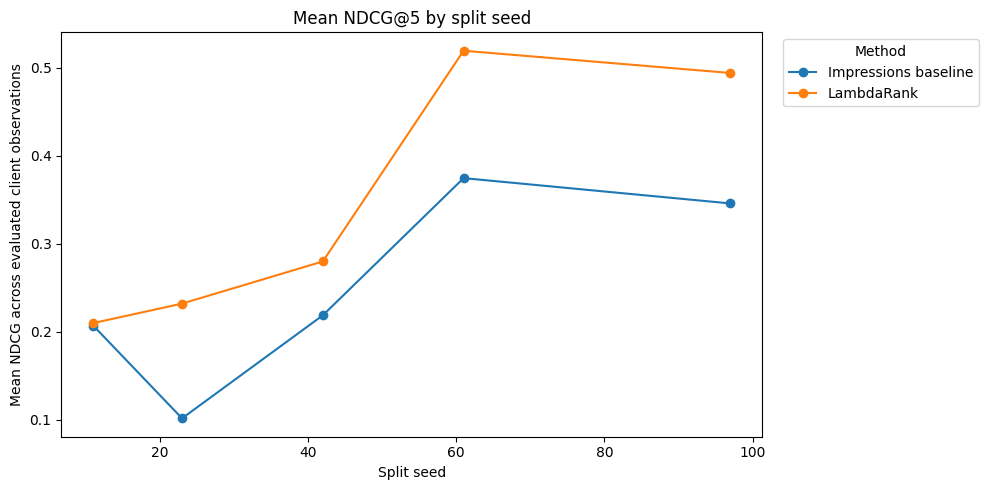

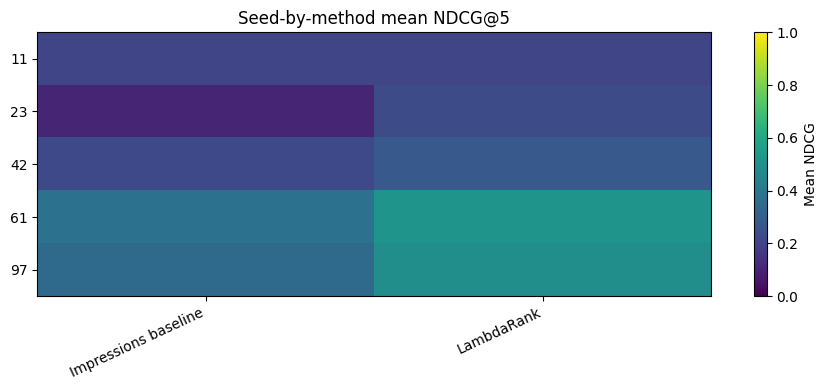

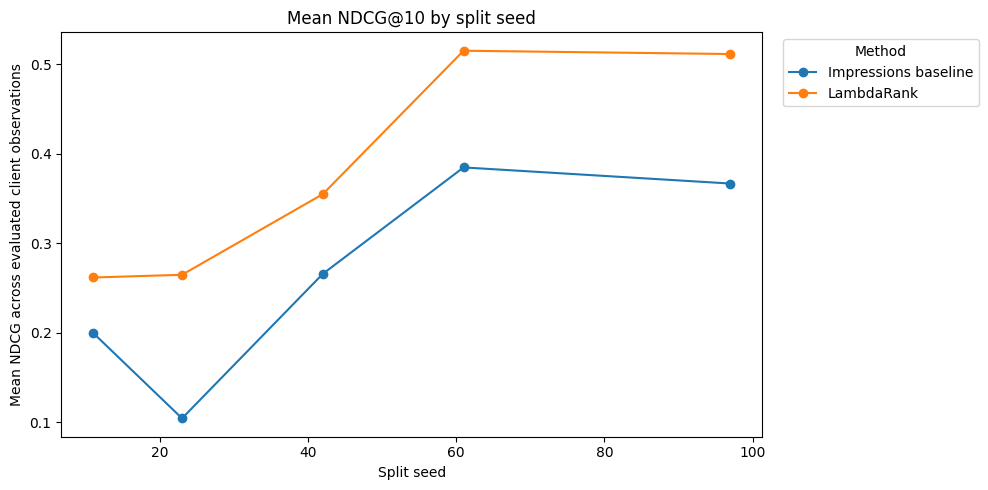

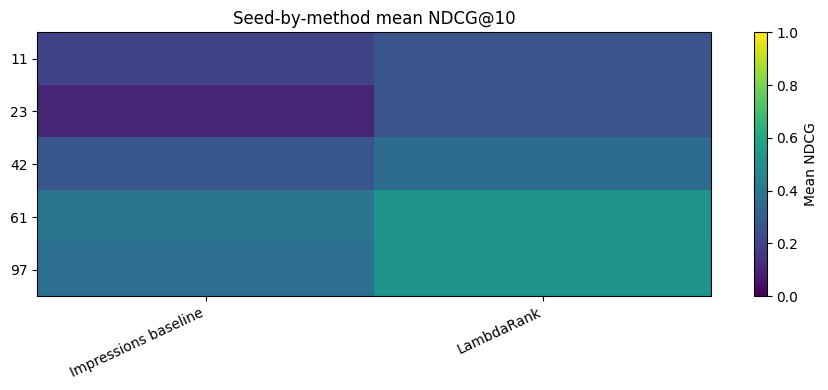

count    mean  median     std     min     max
method_group         k                                                
Impressions baseline 5       5  0.2497  0.2188  0.1113  0.1018  0.3747
                     10      5  0.2643  0.2659  0.1171  0.1043  0.3849
LambdaRank           5       5  0.3471  0.2800  0.1482  0.2100  0.5194
                     10      5  0.3817  0.3550  0.1260  0.2618  0.5154

Split diagnostics schema:


,split_seed,train_clients,test_clients,train_rows_after_cap,train_rows_before_cap,test_rows_full,sampled_train_clients,max_train_group_after_cap
0,11,25,7,41822,52179,26721,1,10000
1,23,25,7,51328,55754,23146,2,10000
2,42,25,7,48108,61446,17454,2,10000
3,61,25,7,34476,44833,34067,1,10000
4,97,25,7,55754,70537,8363,3,10000


Seed presence across diagnostics and NDCG files:


,split_seed,_merge
0,11,both
1,23,both
2,42,both
3,61,both
4,97,both


In [21]:
# Reuse eval_df from Section A if available; otherwise build it from df_ndcg_per_client.
if "eval_df" not in globals():
    eval_df = df_ndcg_per_client.copy()
    eval_df.columns = [str(c).strip() for c in eval_df.columns]
    _client = next((c for c in ["client_hash_id", "client_id", "client"] if c in eval_df.columns), None)
    _seed = next((c for c in ["split_seed", "seed", "split", "split_id"] if c in eval_df.columns), None)
    _method = next((c for c in ["method", "model", "ranking_method", "baseline"] if c in eval_df.columns), None)
    _k = next((c for c in ["k", "cutoff", "top_k"] if c in eval_df.columns), None)
    _score = next((c for c in ["ndcg", "ndcg_score", "score", "value"] if c in eval_df.columns), None)
    if not all([_client, _method, _k, _score]):
        raise ValueError("Cannot identify required columns in df_ndcg_per_client.")
    _rename = {_client:"client_id", _method:"method", _k:"k", _score:"ndcg"}
    if _seed: _rename[_seed] = "split_seed"
    eval_df = eval_df.rename(columns=_rename)
    eval_df["k"] = pd.to_numeric(eval_df["k"], errors="coerce")
    eval_df["ndcg"] = pd.to_numeric(eval_df["ndcg"], errors="coerce")
    eval_df = eval_df.dropna(subset=["client_id", "method", "k", "ndcg"])
    eval_df = eval_df[eval_df["k"].isin([5, 10])]
    if "method_group" not in eval_df.columns:
        def _classify_method(label):
            s = str(label).lower().replace("_", " ").replace("-", " ")
            if "lambda" in s or "ranker" in s: return "LambdaRank"
            if "impression" in s: return "Impressions baseline"
            if "rule" in s: return "Rule-based baseline"
            return None
        eval_df["method_group"] = eval_df["method"].map(_classify_method)
        eval_df = eval_df.dropna(subset=["method_group"])

print("Evaluation columns:", eval_df.columns.tolist())
if "split_seed" not in eval_df.columns:
    print("No split-seed column found in df_ndcg_per_client. Seed-level plots will be skipped; client-level summaries remain available.")
else:
    seed_summary = (
        eval_df.groupby(["split_seed", "method_group", "k"], as_index=False)["ndcg"]
        .agg(mean_ndcg="mean", median_ndcg="median", std_ndcg="std", observations="count")
    )
    display(seed_summary.sort_values(["k", "split_seed", "mean_ndcg"], ascending=[True, True, False]))

    for k_value in sorted(seed_summary["k"].dropna().unique()):
        sub = seed_summary[seed_summary["k"] == k_value]
        pivot = sub.pivot(index="split_seed", columns="method_group", values="mean_ndcg")
        if not pivot.empty:
            ax = pivot.plot(marker="o", figsize=(10, 5))
            ax.set_title(f"Mean NDCG@{int(k_value)} by split seed")
            ax.set_xlabel("Split seed")
            ax.set_ylabel("Mean NDCG across evaluated client observations")
            ax.legend(title="Method", bbox_to_anchor=(1.02, 1), loc="upper left")
            plt.tight_layout()
            plt.show()

            fig, ax = plt.subplots(figsize=(9, max(4, 0.4 * len(pivot))))
            im = ax.imshow(pivot.values, aspect="auto", interpolation="nearest", vmin=0, vmax=1)
            ax.set_xticks(range(len(pivot.columns)), pivot.columns, rotation=25, ha="right")
            ax.set_yticks(range(len(pivot.index)), pivot.index.astype(str))
            ax.set_title(f"Seed-by-method mean NDCG@{int(k_value)}")
            fig.colorbar(im, ax=ax, label="Mean NDCG")
            plt.tight_layout()
            plt.show()

    # Descriptive spread across seed-level means; not a confidence interval.
    display(
        seed_summary.groupby(["method_group", "k"])["mean_ndcg"]
        .agg(["count", "mean", "median", "std", "min", "max"])
        .round(4)
    )

# Compare split diagnostics with per-client evaluation if seed fields exist.
if "df_split_diagnostics" in globals():
    print("Split diagnostics schema:")
    display(df_split_diagnostics.head())
    if "split_seed" in df_split_diagnostics.columns and "split_seed" in eval_df.columns:
        seed_check = df_split_diagnostics[["split_seed"]].drop_duplicates().merge(
            eval_df[["split_seed"]].drop_duplicates(),
            on="split_seed", how="outer", indicator=True
        )
        print("Seed presence across diagnostics and NDCG files:")
        display(seed_check)


## E. Feature relationships and leakage investigation

This section discovers numeric feature columns in the recommendation queue, visualizes correlations, and groups features by name. It excludes identifiers, ranks, scores, and target fields from the feature-correlation heatmap where possible. Correlation is a diagnostic, not proof of leakage.

Queue schema:


,column,dtype
client_hash_id,client_hash_id,object
content_hash_id,content_hash_id,object
model_rank,model_rank,int64
priority_tier,priority_tier,object
recommendation_eligible,recommendation_eligible,bool
high_priority_evidence,high_priority_evidence,bool
historical_decline_evidence,historical_decline_evidence,bool
lambdarank_score,lambdarank_score,float64
baseline_rank,baseline_rank,int64
baseline_score,baseline_score,float64


Numeric columns: 21
Candidate feature columns after exclusions: 12


,feature_1,feature_2,spearman_corr
63,top_query_impressions,kept_query_impressions,0.910533
54,visible_queries,kept_query_impressions,0.878652
0,feat_imp_60_90,feat_imp_90_120,0.837907
55,visible_queries,top_query_share,-0.775122
53,visible_queries,top_query_impressions,0.657449
40,feat_pos_60_90,rare_share,0.647840
41,feat_pos_60_90,anon_share,-0.639766
3,feat_imp_60_90,feat_pos_60_90,-0.635041
56,rare_share,anon_share,-0.629025
9,feat_imp_60_90,kept_query_impressions,0.624068


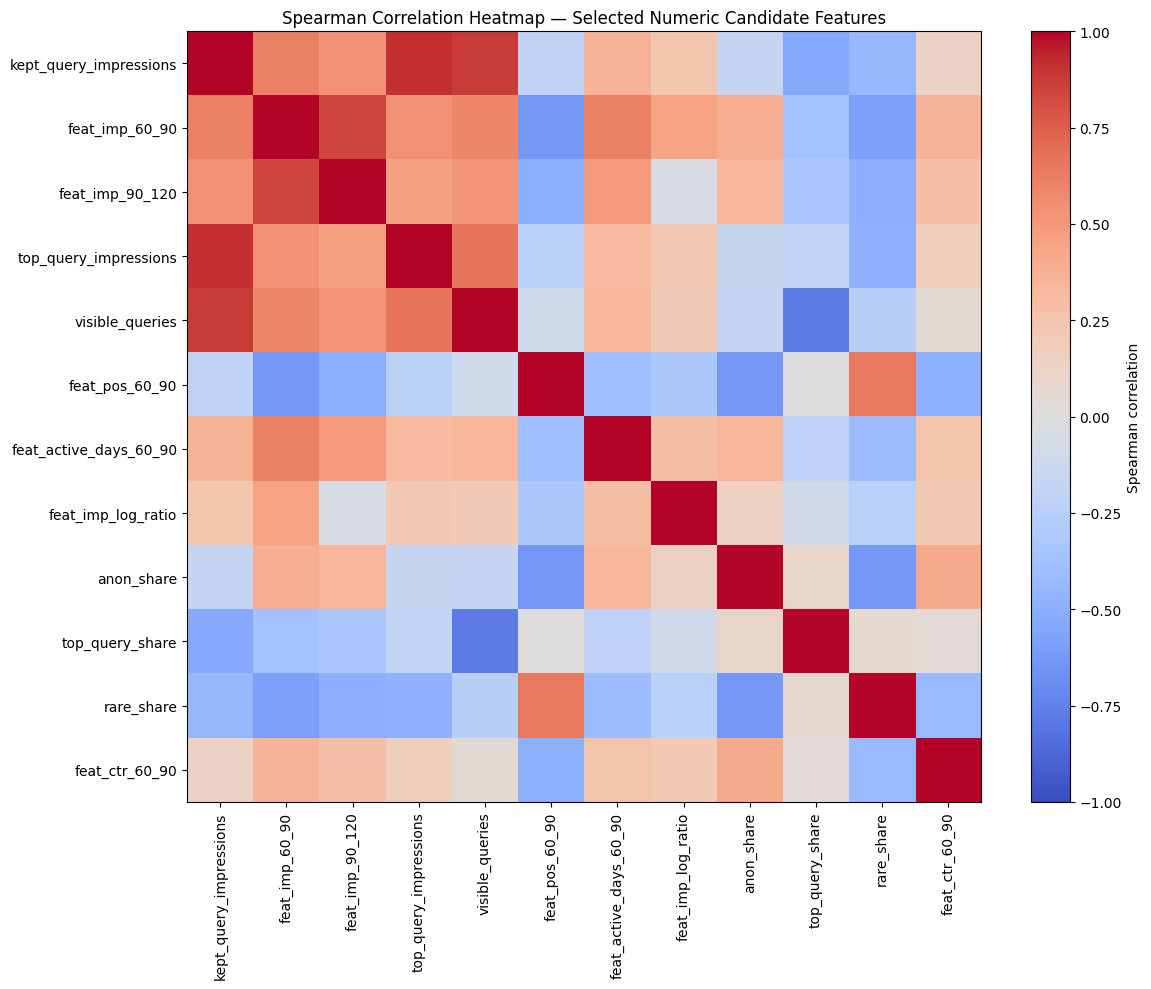

,feature_count
feature_group,
Impressions / traffic,5
Other,3
Coverage / active days,1
CTR,1
Query signals,1
Search position,1


,feature,feature_group
5,feat_ctr_60_90,CTR
3,feat_active_days_60_90,Coverage / active days
0,feat_imp_60_90,Impressions / traffic
1,feat_imp_90_120,Impressions / traffic
2,feat_imp_log_ratio,Impressions / traffic
10,kept_query_impressions,Impressions / traffic
9,top_query_impressions,Impressions / traffic
8,anon_share,Other
7,rare_share,Other
6,visible_queries,Other


In [22]:
queue = df_heldout_queue.copy()
print("Queue schema:")
display(pd.DataFrame({"column": queue.columns, "dtype": queue.dtypes.astype(str)}))

# Identify likely target/label and non-feature columns by name.
target_tokens = ("target_", "label", "relevance", "declining", "is_declining")
nonfeature_tokens = (
    "client_hash_id", "content_hash_id", "client_id", "content_id",
    "url", "title", "rank", "score", "priority", "eligible", "action",
    "target_", "label", "relevance", "declining", "is_declining"
)
numeric_cols = queue.select_dtypes(include=np.number).columns.tolist()
corr_cols = [
    c for c in numeric_cols
    if not any(token in c.lower() for token in nonfeature_tokens)
]
print("Numeric columns:", len(numeric_cols))
print("Candidate feature columns after exclusions:", len(corr_cols))

if len(corr_cols) >= 2:
    corr = queue[corr_cols].corr(method="spearman")
    # Show strongest absolute off-diagonal relationships.
    pairs = []
    for i, col_a in enumerate(corr.columns):
        for col_b in corr.columns[i + 1:]:
            value = corr.loc[col_a, col_b]
            if pd.notna(value):
                pairs.append((col_a, col_b, value, abs(value)))
    strongest = pd.DataFrame(pairs, columns=["feature_1", "feature_2", "spearman_corr", "abs_corr"])
    if not strongest.empty:
        display(strongest.sort_values("abs_corr", ascending=False).head(20).drop(columns="abs_corr"))

    # Plot a readable heatmap of up to 25 candidate features with highest variance.
    selected = queue[corr_cols].var(numeric_only=True).sort_values(ascending=False).head(25).index.tolist()
    corr_small = queue[selected].corr(method="spearman")
    fig, ax = plt.subplots(figsize=(12, 10))
    im = ax.imshow(corr_small.values, vmin=-1, vmax=1, cmap="coolwarm", aspect="auto")
    ax.set_xticks(range(len(selected)), selected, rotation=90)
    ax.set_yticks(range(len(selected)), selected)
    ax.set_title("Spearman Correlation Heatmap — Selected Numeric Candidate Features")
    fig.colorbar(im, ax=ax, label="Spearman correlation")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough numeric candidate feature columns for a correlation heatmap.")

# Feature-group summary by name patterns; useful for interpretation, not a semantic guarantee.
def feature_group(name):
    s = name.lower()
    if "impression" in s or "imp_" in s: return "Impressions / traffic"
    if "click" in s: return "Clicks"
    if "ctr" in s: return "CTR"
    if "position" in s or "pos_" in s: return "Search position"
    if "volatility" in s: return "Volatility"
    if "query" in s: return "Query signals"
    if "active_days" in s or "observed_days" in s: return "Coverage / active days"
    if "word" in s or "title" in s or "content" in s: return "Content metadata"
    return "Other"

feature_groups = pd.DataFrame({"feature": corr_cols})
if len(feature_groups):
    feature_groups["feature_group"] = feature_groups["feature"].map(feature_group)
    display(feature_groups.groupby("feature_group").size().sort_values(ascending=False).rename("feature_count").to_frame())
    display(feature_groups.sort_values(["feature_group", "feature"]))


### Leakage review checklist

Correlation plots alone cannot establish leakage. Open the training notebook and record:
- exact historical feature windows (e.g. 60–90 and 90–120 days before the reference date);
- exact target-label window and reference date;
- whether any feature includes data from the label window;
- whether target-derived columns are excluded from the model feature list;
- whether preprocessing is fitted on training data only.

Do not mark leakage as present or absent until these time boundaries and feature-selection code are checked.

In [23]:
# A small template to document the window audit after inspecting the training notebook.
leakage_review = pd.DataFrame([
    {"check": "Feature windows end before target window begins", "status": "REVIEW_REQUIRED", "evidence": "Confirm in training notebook SQL/code"},
    {"check": "Target-derived columns excluded from model features", "status": "REVIEW_REQUIRED", "evidence": "Inspect final feature list"},
    {"check": "Imputer/preprocessing fitted on training rows only", "status": "REVIEW_REQUIRED", "evidence": "Inspect split and pipeline fitting"},
    {"check": "Evaluation uses held-out clients/splits", "status": "REVIEW_REQUIRED", "evidence": "Inspect split-generation and evaluation code"},
])
display(leakage_review)


,check,status,evidence
0,Feature windows end before target window begins,REVIEW_REQUIRED,Confirm in training notebook SQL/code
1,Target-derived columns excluded from model fea...,REVIEW_REQUIRED,Inspect final feature list
2,Imputer/preprocessing fitted on training rows ...,REVIEW_REQUIRED,Inspect split and pipeline fitting
3,Evaluation uses held-out clients/splits,REVIEW_REQUIRED,Inspect split-generation and evaluation code


## F. Recommendation quality and data-quality audit

The following checks create a compact scorecard for identifiers, duplicate client-content keys, score validity, rank consistency, priority/eligibility compatibility, and missingness. Findings are diagnostic: review failures before changing the pipeline.

,check,passed,details
0,Client identifier present,True,missing/blank=0
1,Content identifier present,True,missing/blank=0
2,Unique client-content keys,True,duplicate pairs=0
3,Model scores finite and nonmissing,True,invalid/missing=0
4,Ranks are positive integers,True,invalid/missing=0
5,Ranks unique within client,True,duplicate client-rank pairs=0
6,Ineligible rows use non-actionable tier,True,ineligible rows with other tiers=0


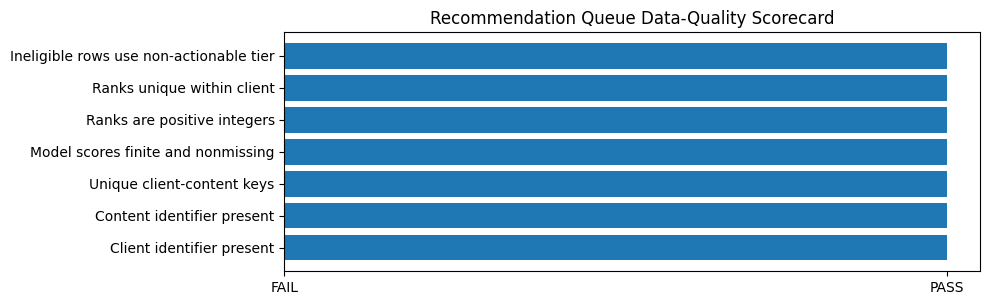

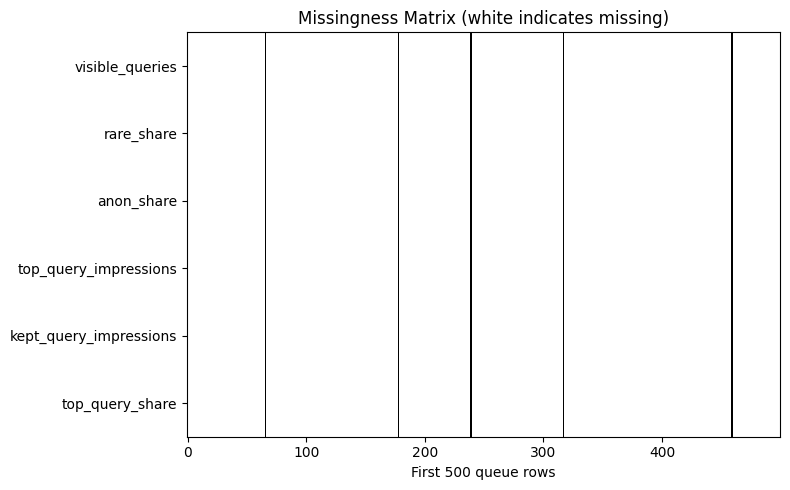

In [24]:
quality_checks = []

def record_quality_check(check, passed, details):
    quality_checks.append({
        "check": check,
        "passed": bool(passed),
        "details": str(details)
    })

queue = df_heldout_queue.copy()
client_key = next((c for c in ["client_hash_id", "client_id", "client"] if c in queue.columns), None)
content_key = next((c for c in ["content_hash_id", "content_id", "page_id"] if c in queue.columns), None)
score_key = next((c for c in ["lambdarank_score", "ranker_score", "model_score", "score"] if c in queue.columns), None)
rank_key = next((c for c in ["model_rank", "rank", "rank_position"] if c in queue.columns), None)
tier_key = next((c for c in ["priority_tier", "priority", "tier"] if c in queue.columns), None)
eligible_key = next((c for c in ["recommendation_eligible", "eligible", "is_eligible"] if c in queue.columns), None)

for key_name, col in [("Client identifier", client_key), ("Content identifier", content_key)]:
    if col:
        missing = int(queue[col].isna().sum() + queue[col].astype("string").str.strip().eq("").sum())
        record_quality_check(f"{key_name} present", missing == 0, f"missing/blank={missing}")
    else:
        record_quality_check(f"{key_name} column exists", False, "No recognized identifier column")

if client_key and content_key:
    dup = int(queue.duplicated([client_key, content_key]).sum())
    record_quality_check("Unique client-content keys", dup == 0, f"duplicate pairs={dup}")

if score_key:
    scores = pd.to_numeric(queue[score_key], errors="coerce")
    invalid = int(scores.isna().sum() + np.isinf(scores.dropna()).sum())
    record_quality_check("Model scores finite and nonmissing", invalid == 0, f"invalid/missing={invalid}")
else:
    record_quality_check("Model score column exists", False, "No recognized score column")

if rank_key:
    ranks = pd.to_numeric(queue[rank_key], errors="coerce")
    invalid = int(ranks.isna().sum() + (ranks.dropna() < 1).sum() + (ranks.dropna() % 1 != 0).sum())
    record_quality_check("Ranks are positive integers", invalid == 0, f"invalid/missing={invalid}")
    if client_key:
        dup_ranks = int(queue.duplicated([client_key, rank_key]).sum())
        record_quality_check("Ranks unique within client", dup_ranks == 0, f"duplicate client-rank pairs={dup_ranks}")
else:
    record_quality_check("Rank column exists", False, "No recognized rank column")

if tier_key and eligible_key:
    elig = queue[eligible_key].astype("string").str.lower().isin(["true", "1", "yes", "eligible"])
    ineligible_tier = queue[tier_key].astype("string").str.upper().isin(["NOT_ELIGIBLE", "INELIGIBLE", "NOT ELIGIBLE"])
    bad = int((~elig & ~ineligible_tier).sum())
    record_quality_check("Ineligible rows use non-actionable tier", bad == 0, f"ineligible rows with other tiers={bad}")

quality_df = pd.DataFrame(quality_checks)
display(quality_df)

fig, ax = plt.subplots(figsize=(10, max(3, 0.45 * len(quality_df))))
status = quality_df["passed"].astype(int).values
ax.barh(quality_df["check"], status)
ax.set_xlim(0, 1.05)
ax.set_xticks([0, 1], ["FAIL", "PASS"])
ax.set_title("Recommendation Queue Data-Quality Scorecard")
plt.tight_layout()
plt.show()

# Missingness matrix for a manageable sample of rows and columns.
missing_cols = [c for c in queue.columns if queue[c].isna().any()]
if missing_cols:
    sample = queue[missing_cols].head(500)
    fig, ax = plt.subplots(figsize=(min(16, max(8, 0.35 * len(missing_cols))), 5))
    ax.imshow(sample.isna().T.values, aspect="auto", interpolation="nearest", cmap="gray_r")
    ax.set_yticks(range(len(missing_cols)), missing_cols)
    ax.set_xlabel("First 500 queue rows")
    ax.set_title("Missingness Matrix (white indicates missing)")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values detected in the recommendation queue.")


In [25]:
if tier_key and eligible_key:
    eligibility_table = pd.crosstab(
        queue[tier_key].fillna("MISSING"),
        queue[eligible_key].astype("string").fillna("MISSING"),
        margins=True
    )
    print("Priority tier versus eligibility:")
    display(eligibility_table)

# Evidence-field audit: only report fields that actually exist.
evidence_candidates = [
    "target_trend_pct", "target_imp_prev30", "target_imp_last30",
    "high_priority_evidence", "historical_decline_evidence",
    "suggested_action", "reason", "recommendation_reason"
]
evidence_cols = [c for c in evidence_candidates if c in queue.columns]
print("Available evidence/action fields:", evidence_cols)
if evidence_cols:
    display(queue[evidence_cols].head(20))


Priority tier versus eligibility:


recommendation_eligible,False,True,All
priority_tier,,,
HIGH,0,6,6
LOW,0,7835,7835
MEDIUM,0,75,75
NOT_ELIGIBLE,447,0,447
All,447,7916,8363


Available evidence/action fields: ['target_trend_pct', 'target_imp_prev30', 'target_imp_last30', 'high_priority_evidence', 'historical_decline_evidence', 'suggested_action']


,target_trend_pct,target_imp_prev30,target_imp_last30,high_priority_evidence,historical_decline_evidence,suggested_action
0,-0.924834,3478.0,261.428571,False,False,"Review search intent, title/meta description, ..."
1,-0.516973,1414.0,683.000000,False,False,"Review search intent, title/meta description, ..."
2,-0.920404,4622.0,367.894737,False,False,"Review search intent, title/meta description, ..."
3,-0.734382,543.0,144.230769,False,False,"Review search intent, title/meta description, ..."
4,-0.955730,1177.0,52.105263,False,False,"Review search intent, title/meta description, ..."
5,-0.808584,1165.0,223.000000,False,False,"Review search intent, title/meta description, ..."
6,-0.923508,1961.0,150.000000,False,False,"Review search intent, title/meta description, ..."
7,-0.751669,754.0,187.241379,False,False,"Review search intent, title/meta description, ..."
8,-0.716049,810.0,230.000000,False,False,"Review search intent, title/meta description, ..."
9,-0.775848,3685.0,826.000000,False,False,"Review search intent, title/meta description, ..."


## G. Business-facing opportunity analysis

These plots describe historical traffic and search-performance signals by priority tier, when those fields are present in the exported queue. They are not forecasts of refresh impact. Missing fields are skipped with a message.

Detected business-facing metrics: {'Impressions (previous window)': 'target_imp_prev30', 'Impressions (latest window)': 'target_imp_last30', 'Average position': 'feat_pos_60_90'}


,metric,source_column,priority_tier,count,mean,median
0,Impressions (previous window),target_imp_prev30,HIGH,6,1875.633333,1426.000000
1,Impressions (previous window),target_imp_prev30,LOW,7835,1896.225855,520.000000
2,Impressions (previous window),target_imp_prev30,MEDIUM,75,2377.310476,1038.000000
3,Impressions (previous window),target_imp_prev30,NOT_ELIGIBLE,447,218.097638,142.758621
4,Impressions (latest window),target_imp_last30,HIGH,6,2270.691026,1210.476923
5,Impressions (latest window),target_imp_last30,LOW,7835,1210.218246,274.000000
6,Impressions (latest window),target_imp_last30,MEDIUM,75,1676.039114,385.714286
7,Impressions (latest window),target_imp_last30,NOT_ELIGIBLE,447,211.536036,128.823529
8,Average position,feat_pos_60_90,HIGH,6,8.412449,8.217640
9,Average position,feat_pos_60_90,LOW,7835,15.542873,8.721805


/tmp/ipykernel_564/2530300739.py:43: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data_to_plot, labels=[str(t) for t in tiers], showfliers=False)


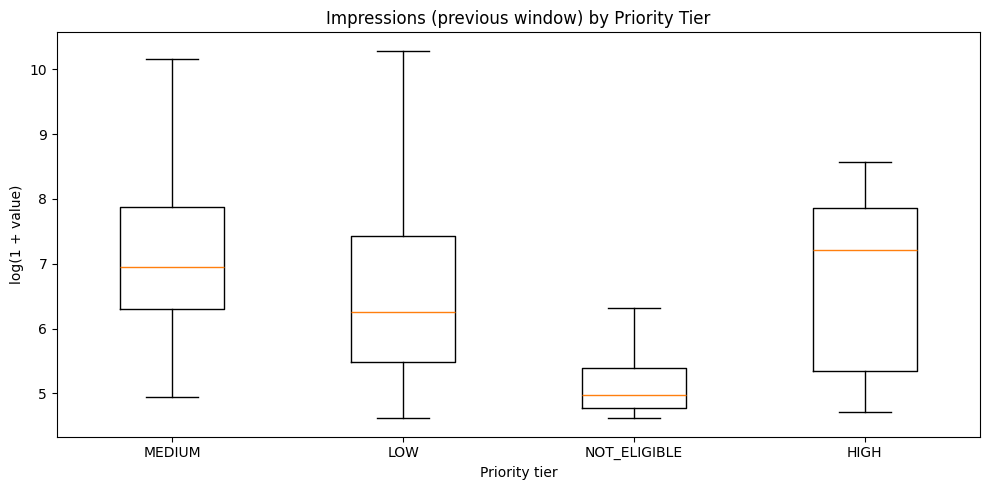

/tmp/ipykernel_564/2530300739.py:43: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data_to_plot, labels=[str(t) for t in tiers], showfliers=False)


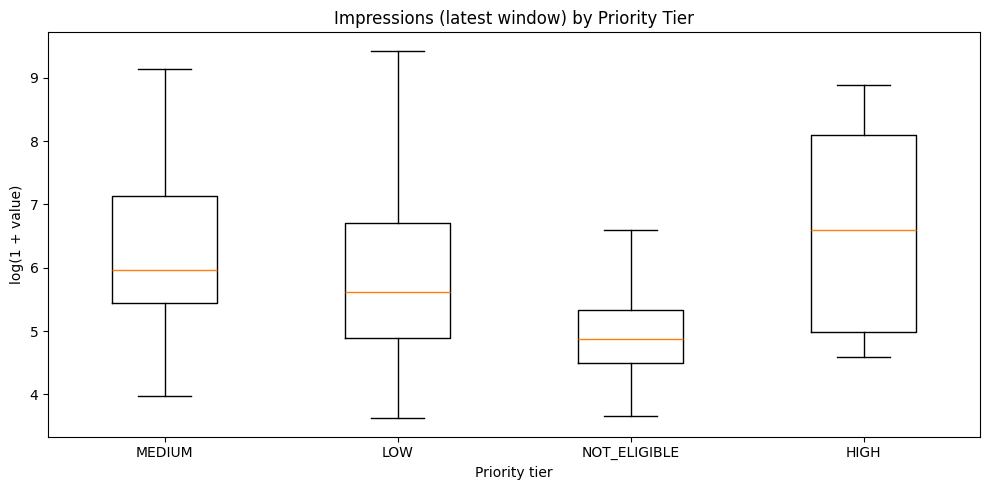

/tmp/ipykernel_564/2530300739.py:43: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data_to_plot, labels=[str(t) for t in tiers], showfliers=False)


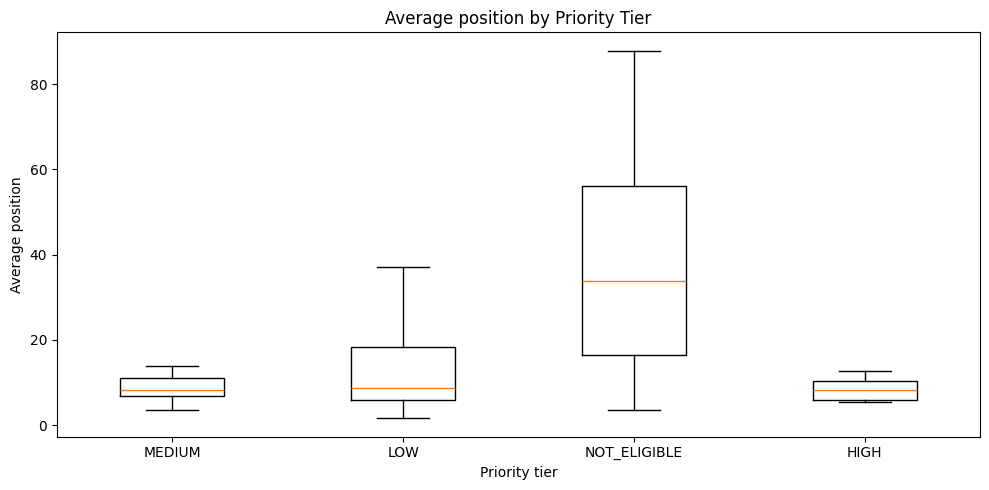

,queue_rows,share_pct,cumulative_share_pct
client_hash_id,,,
client_08a6a72ff48e62c0,5189,62.05,62.05
client_3f0ce4d44fe94f3d,1534,18.34,80.39
client_1a730cb2640a1abf,1054,12.60,92.99
client_ff644d8251367cbb,562,6.72,99.71
client_08d2847f24cf89c1,13,0.16,99.87
client_86ebc2f12c01f586,7,0.08,99.95
client_ccdd78843409c8c7,4,0.05,100.00


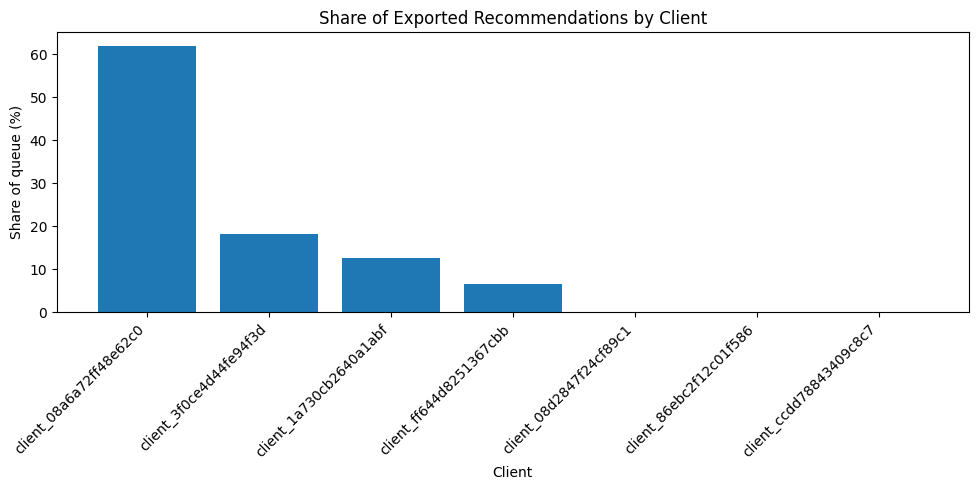

In [26]:
queue = df_heldout_queue.copy()
tier_key = next((c for c in ["priority_tier", "priority", "tier"] if c in queue.columns), None)

metric_aliases = {
    "Impressions (previous window)": ["target_imp_prev30", "impressions_prev30", "feat_imp_60_90", "impressions"],
    "Impressions (latest window)": ["target_imp_last30", "impressions_last30", "feat_imp_30_60"],
    "Clicks": ["target_clicks_last30", "clicks_last30", "feat_clicks_60_90", "clicks"],
    "Average position": ["target_position_last30", "avg_position_last30", "feat_pos_60_90", "average_position", "avg_position"],
}
selected_metrics = {}
for label, candidates in metric_aliases.items():
    col = next((c for c in candidates if c in queue.columns), None)
    if col:
        selected_metrics[label] = col

print("Detected business-facing metrics:", selected_metrics)
if tier_key and selected_metrics:
    summary_rows = []
    for label, col in selected_metrics.items():
        queue[col] = pd.to_numeric(queue[col], errors="coerce")
        tmp = queue.groupby(tier_key, dropna=False)[col].agg(["count", "mean", "median"])
        tmp = tmp.reset_index().rename(columns={tier_key: "priority_tier"})
        tmp["metric"] = label
        tmp["source_column"] = col
        summary_rows.append(tmp)
    business_summary = pd.concat(summary_rows, ignore_index=True)
    display(business_summary[["metric", "source_column", "priority_tier", "count", "mean", "median"]])

    for label, col in selected_metrics.items():
        plot_data = queue[[tier_key, col]].dropna().copy()
        if plot_data.empty:
            continue
        # Log scale for highly skewed traffic counts, preserving zero values through log1p.
        if "impression" in label.lower() or "click" in label.lower():
            plot_data["_plot_value"] = np.log1p(plot_data[col].clip(lower=0))
            y_label = "log(1 + value)"
        else:
            plot_data["_plot_value"] = plot_data[col]
            y_label = label
        tiers = plot_data[tier_key].dropna().unique().tolist()
        data_to_plot = [plot_data.loc[plot_data[tier_key] == t, "_plot_value"].values for t in tiers]
        plt.figure(figsize=(10, 5))
        plt.boxplot(data_to_plot, labels=[str(t) for t in tiers], showfliers=False)
        plt.title(f"{label} by Priority Tier")
        plt.xlabel("Priority tier")
        plt.ylabel(y_label)
        plt.tight_layout()
        plt.show()
else:
    print("Skipping tier-by-metric plots: no priority tier or recognized historical metric columns found.")

# Recommendation concentration by client
client_key = next((c for c in ["client_hash_id", "client_id", "client"] if c in queue.columns), None)
if client_key:
    client_volume = queue.groupby(client_key).size().sort_values(ascending=False)
    total = client_volume.sum()
    concentration = pd.DataFrame({
        "queue_rows": client_volume,
        "share_pct": (100 * client_volume / total).round(2),
        "cumulative_share_pct": (100 * client_volume.cumsum() / total).round(2)
    })
    display(concentration)
    plt.figure(figsize=(10, 5))
    plt.bar(concentration.index.astype(str), concentration["share_pct"])
    plt.title("Share of Exported Recommendations by Client")
    plt.xlabel("Client")
    plt.ylabel("Share of queue (%)")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


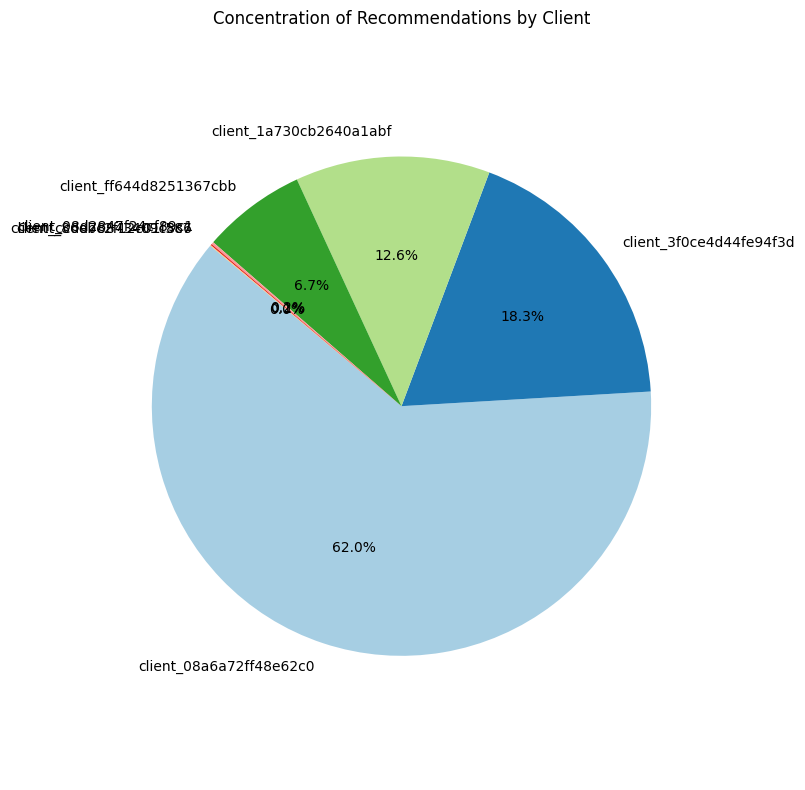

In [27]:
import matplotlib.pyplot as plt

if 'df_heldout_queue' in globals():
    queue = df_heldout_queue.copy()
    client_key = next((c for c in ["client_hash_id", "client_id", "client"] if c in queue.columns), None)

    if client_key:
        client_volume = queue.groupby(client_key).size().sort_values(ascending=False)

        plt.figure(figsize=(8, 8))
        plt.pie(client_volume, labels=client_volume.index, autopct='%1.1f%%', startangle=140, colors=plt.cm.Paired.colors)
        plt.title("Concentration of Recommendations by Client")
        plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.
        plt.tight_layout()
        plt.show()
    else:
        print("Client identifier column not found.")
else:
    print("df_heldout_queue is not loaded.")